# Lab 1 — Multiclass Classification

Kaggle experiments completed through tuning, regularization, and frozen test evaluation. Final fresh-session reproducibility review remains.

## 1. Multiclass target and dataset source

Predict `Failure Type` (six classes) from the Kaggle predictive-maintenance CSV. The binary `Target` column is excluded from inputs.

In [1]:
%pip install -q skorch imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Environment, seeds, and device

Record package versions and device; seed Python, NumPy, and PyTorch with 42.

In [2]:
import random
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Python:", platform.python_version())
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for package in [
    "torch", "scikit-learn", "skorch", "pandas",
    "numpy", "matplotlib", "seaborn", "imbalanced-learn"
]:
    print(f"{package}: {version(package)}")

Python: 3.13.15
Device: cuda
GPU: Tesla T4
torch: 2.11.0+cu128
scikit-learn: 1.6.1
skorch: 1.4.0
pandas: 2.3.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
imbalanced-learn: 0.14.2


## 3. Load data, inspect schema, and exclude leaking columns

Exclude UDI, Product ID, and binary Target. Retain supplied failure-type labels, documenting 27 disagreements with the binary label.

In [3]:
DATA_PATH = Path(
    "/kaggle/input/datasets/shivamb/"
    "machine-predictive-maintenance-classification/"
    "predictive_maintenance.csv"
)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

maintenance = pd.read_csv(DATA_PATH)

print("Shape:", maintenance.shape)
print("Columns:", maintenance.columns.tolist())
display(maintenance.head())

assert "Failure Type" in maintenance.columns, "Expected target column missing."
assert maintenance["Failure Type"].notna().all(), "Missing target labels."

print("\nMulticlass target distribution:")
print(maintenance["Failure Type"].value_counts(dropna=False))

Shape: (10000, 10)
Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure



Multiclass target distribution:
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


In [4]:
TARGET = "Failure Type"

NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
EXCLUDED_COLUMNS = ["UDI", "Product ID", "Target"]

required_columns = FEATURES + EXCLUDED_COLUMNS + [TARGET]
missing_columns = set(required_columns) - set(maintenance.columns)

assert not missing_columns, f"Missing columns: {missing_columns}"

print("DATASET SIZE")
print("Rows:", len(maintenance))
print("Columns:", maintenance.shape[1])

column_summary = pd.DataFrame({
    "dtype": maintenance.dtypes.astype(str),
    "missing_count": maintenance.isna().sum(),
    "unique_values": maintenance.nunique(),
})

display(column_summary)

print("DUPLICATE CHECKS")
print("Fully duplicated rows:", maintenance.duplicated().sum())
print("Repeated UDI values:", maintenance["UDI"].duplicated().sum())
print(
    "Repeated feature combinations:",
    maintenance.duplicated(subset=FEATURES).sum(),
)

print("\nNUMERIC VALIDITY")
print(
    "Rows containing non-finite numeric features:",
    (~np.isfinite(maintenance[NUMERIC_FEATURES]).all(axis=1)).sum(),
)

print("\nPRODUCT TYPES")
print(maintenance["Type"].value_counts(dropna=False))

print("\nTARGET CLASSES")
print(maintenance[TARGET].value_counts(dropna=False))

DATASET SIZE
Rows: 10000
Columns: 10


,dtype,missing_count,unique_values
UDI,int64,0,10000
Product ID,object,0,10000
Type,object,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Target,int64,0,2
Failure Type,object,0,6


DUPLICATE CHECKS
Fully duplicated rows: 0
Repeated UDI values: 0
Repeated feature combinations: 0

NUMERIC VALIDITY
Rows containing non-finite numeric features: 0

PRODUCT TYPES
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

TARGET CLASSES
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


In [5]:
validity_checks = pd.Series({
    "Non-positive air temperature": (
        maintenance["Air temperature [K]"] <= 0
    ).sum(),
    "Non-positive process temperature": (
        maintenance["Process temperature [K]"] <= 0
    ).sum(),
    "Non-positive rotational speed": (
        maintenance["Rotational speed [rpm]"] <= 0
    ).sum(),
    "Negative torque": (
        maintenance["Torque [Nm]"] < 0
    ).sum(),
    "Negative tool wear": (
        maintenance["Tool wear [min]"] < 0
    ).sum(),
    "Unexpected product type": (
        ~maintenance["Type"].isin(["L", "M", "H"])
    ).sum(),
    "Unexpected binary target": (
        ~maintenance["Target"].isin([0, 1])
    ).sum(),
})

print("VALIDITY CHECKS")
display(validity_checks.to_frame("row_count"))

print("BINARY TARGET VS FAILURE TYPE")
display(pd.crosstab(
    maintenance["Failure Type"],
    maintenance["Target"],
    margins=True,
))

failure_from_type = maintenance[TARGET].ne("No Failure").astype(int)
label_disagreements = maintenance.loc[
    maintenance["Target"].ne(failure_from_type),
    ["UDI", "Target", TARGET],
]

print("Rows where the two labels disagree:", len(label_disagreements))
display(label_disagreements.head(20))

VALIDITY CHECKS


,row_count
Non-positive air temperature,0
Non-positive process temperature,0
Non-positive rotational speed,0
Negative torque,0
Negative tool wear,0
Unexpected product type,0
Unexpected binary target,0


BINARY TARGET VS FAILURE TYPE


Target,0,1,All
Failure Type,,,
Heat Dissipation Failure,0,112,112
No Failure,9643,9,9652
Overstrain Failure,0,78,78
Power Failure,0,95,95
Random Failures,18,0,18
Tool Wear Failure,0,45,45
All,9661,339,10000


Rows where the two labels disagree: 27


,UDI,Target,Failure Type
1221,1222,0,Random Failures
1302,1303,0,Random Failures
1437,1438,1,No Failure
1748,1749,0,Random Failures
2072,2073,0,Random Failures
2559,2560,0,Random Failures
2749,2750,1,No Failure
3065,3066,0,Random Failures
3452,3453,0,Random Failures
4044,4045,1,No Failure


## 4. Stratified splits and exploratory analysis

Use 6,000 training, 2,000 validation, and 2,000 test rows. Explore training features and retain the test set for final evaluation.

In [6]:
from sklearn.model_selection import train_test_split

classification_data = maintenance[FEATURES + [TARGET]].copy()

development, test = train_test_split(
    classification_data,
    test_size=0.20,
    stratify=classification_data[TARGET],
    random_state=SEED,
)

train, validation = train_test_split(
    development,
    test_size=0.25,
    stratify=development[TARGET],
    random_state=SEED,
)

assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)
assert len(train) + len(validation) + len(test) == len(maintenance)
assert not set(EXCLUDED_COLUMNS).intersection(FEATURES)

class_names = sorted(classification_data[TARGET].unique())

class_counts = pd.DataFrame({
    name: partition[TARGET].value_counts().reindex(
        class_names, fill_value=0
    )
    for name, partition in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
})

assert (class_counts > 0).all().all()

print("PARTITION SIZES")
print({
    "train": len(train),
    "validation": len(validation),
    "test": len(test),
})

print("\nCLASS COUNTS")
display(class_counts)

print("Smallest training class:", class_counts["train"].min())
print("PASS: disjoint partitions; all six classes present in each.")

RESULTS_DIR = Path("/kaggle/working/results")
PLOT_DIR = Path("/kaggle/working/plots")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

class_counts.to_csv(
    RESULTS_DIR / "maintenance_split_class_counts.csv"
)

split_assignments = pd.concat([
    pd.DataFrame({
        "UDI": maintenance.loc[partition.index, "UDI"].to_numpy(),
        "split": name,
    })
    for name, partition in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
])

split_assignments.to_csv(
    RESULTS_DIR / "maintenance_split_assignments.csv",
    index=False,
)

label_disagreements.to_csv(
    RESULTS_DIR / "maintenance_label_disagreements.csv",
    index=False,
)

PARTITION SIZES
{'train': 6000, 'validation': 2000, 'test': 2000}

CLASS COUNTS


,train,validation,test
Failure Type,,,
Heat Dissipation Failure,67,23,22
No Failure,5792,1930,1930
Overstrain Failure,46,16,16
Power Failure,57,19,19
Random Failures,11,3,4
Tool Wear Failure,27,9,9


Smallest training class: 11
PASS: disjoint partitions; all six classes present in each.


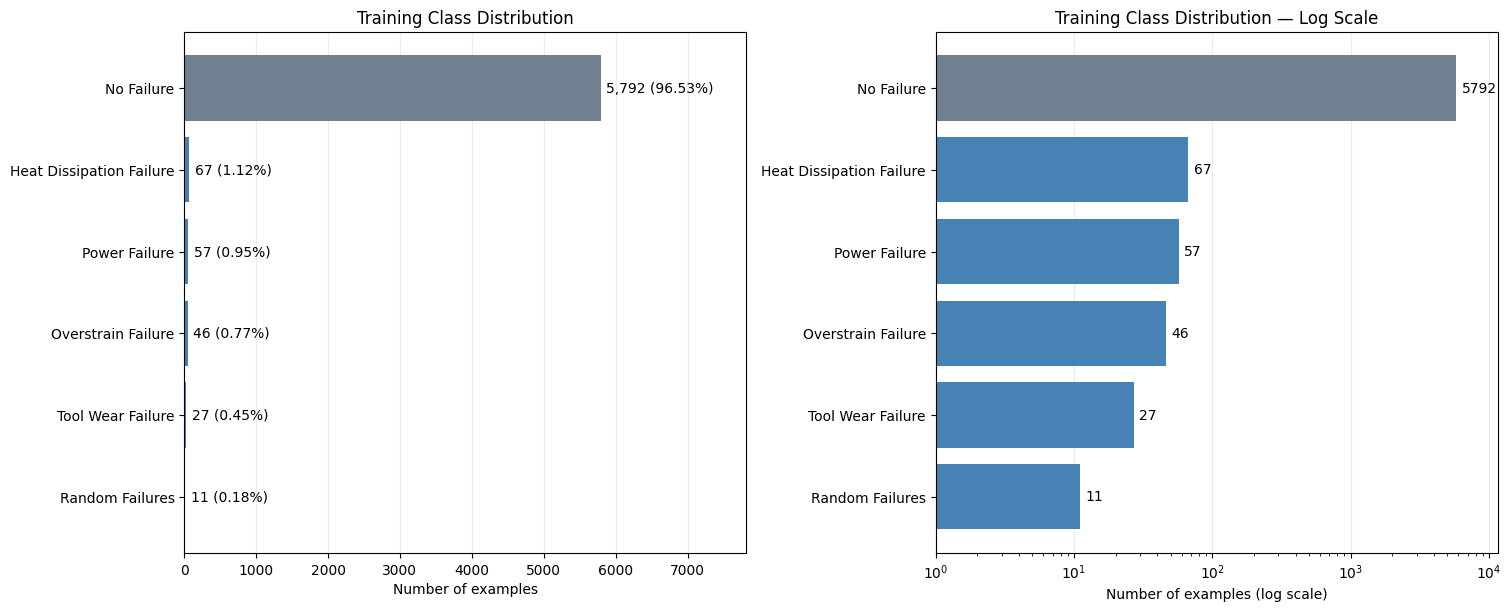

Largest-to-smallest training class ratio: 526.5


In [7]:
import matplotlib.pyplot as plt

training_counts = class_counts["train"].sort_values(ascending=False)
training_percentages = training_counts / len(train) * 100

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), constrained_layout=True
)

colors = [
    "slategray" if name == "No Failure" else "steelblue"
    for name in training_counts.index
]

for ax in axes:
    bars = ax.barh(
        training_counts.index,
        training_counts.values,
        color=colors,
    )
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

axes[0].bar_label(
    axes[0].containers[0],
    labels=[
        f"{count:,} ({percentage:.2f}%)"
        for count, percentage in zip(
            training_counts, training_percentages
        )
    ],
    padding=4,
)
axes[0].set_xlim(0, training_counts.max() * 1.35)
axes[0].set_title("Training Class Distribution")
axes[0].set_xlabel("Number of examples")

axes[1].set_xscale("log")
axes[1].set_xlim(1, training_counts.max() * 2)
axes[1].bar_label(axes[1].containers[0], padding=4)
axes[1].set_title("Training Class Distribution — Log Scale")
axes[1].set_xlabel("Number of examples (log scale)")

fig.savefig(
    PLOT_DIR / "maintenance_training_class_distribution.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print(
    "Largest-to-smallest training class ratio:",
    round(training_counts.max() / training_counts.min(), 1),
)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Air temperature [K],6000.0,299.984,2.021,295.3,295.800,298.3,300.0,301.5,304.100,304.4
Process temperature [K],6000.0,309.993,1.490,305.7,306.500,308.8,310.1,311.1,313.300,313.8
Rotational speed [rpm],6000.0,1534.979,177.108,1168.0,1271.000,1421.0,1500.0,1609.0,2165.090,2833.0
Torque [Nm],6000.0,40.176,9.991,5.6,16.899,33.4,40.3,47.0,63.402,76.6
Tool wear [min],6000.0,107.910,63.391,0.0,0.000,54.0,108.0,162.0,223.000,246.0


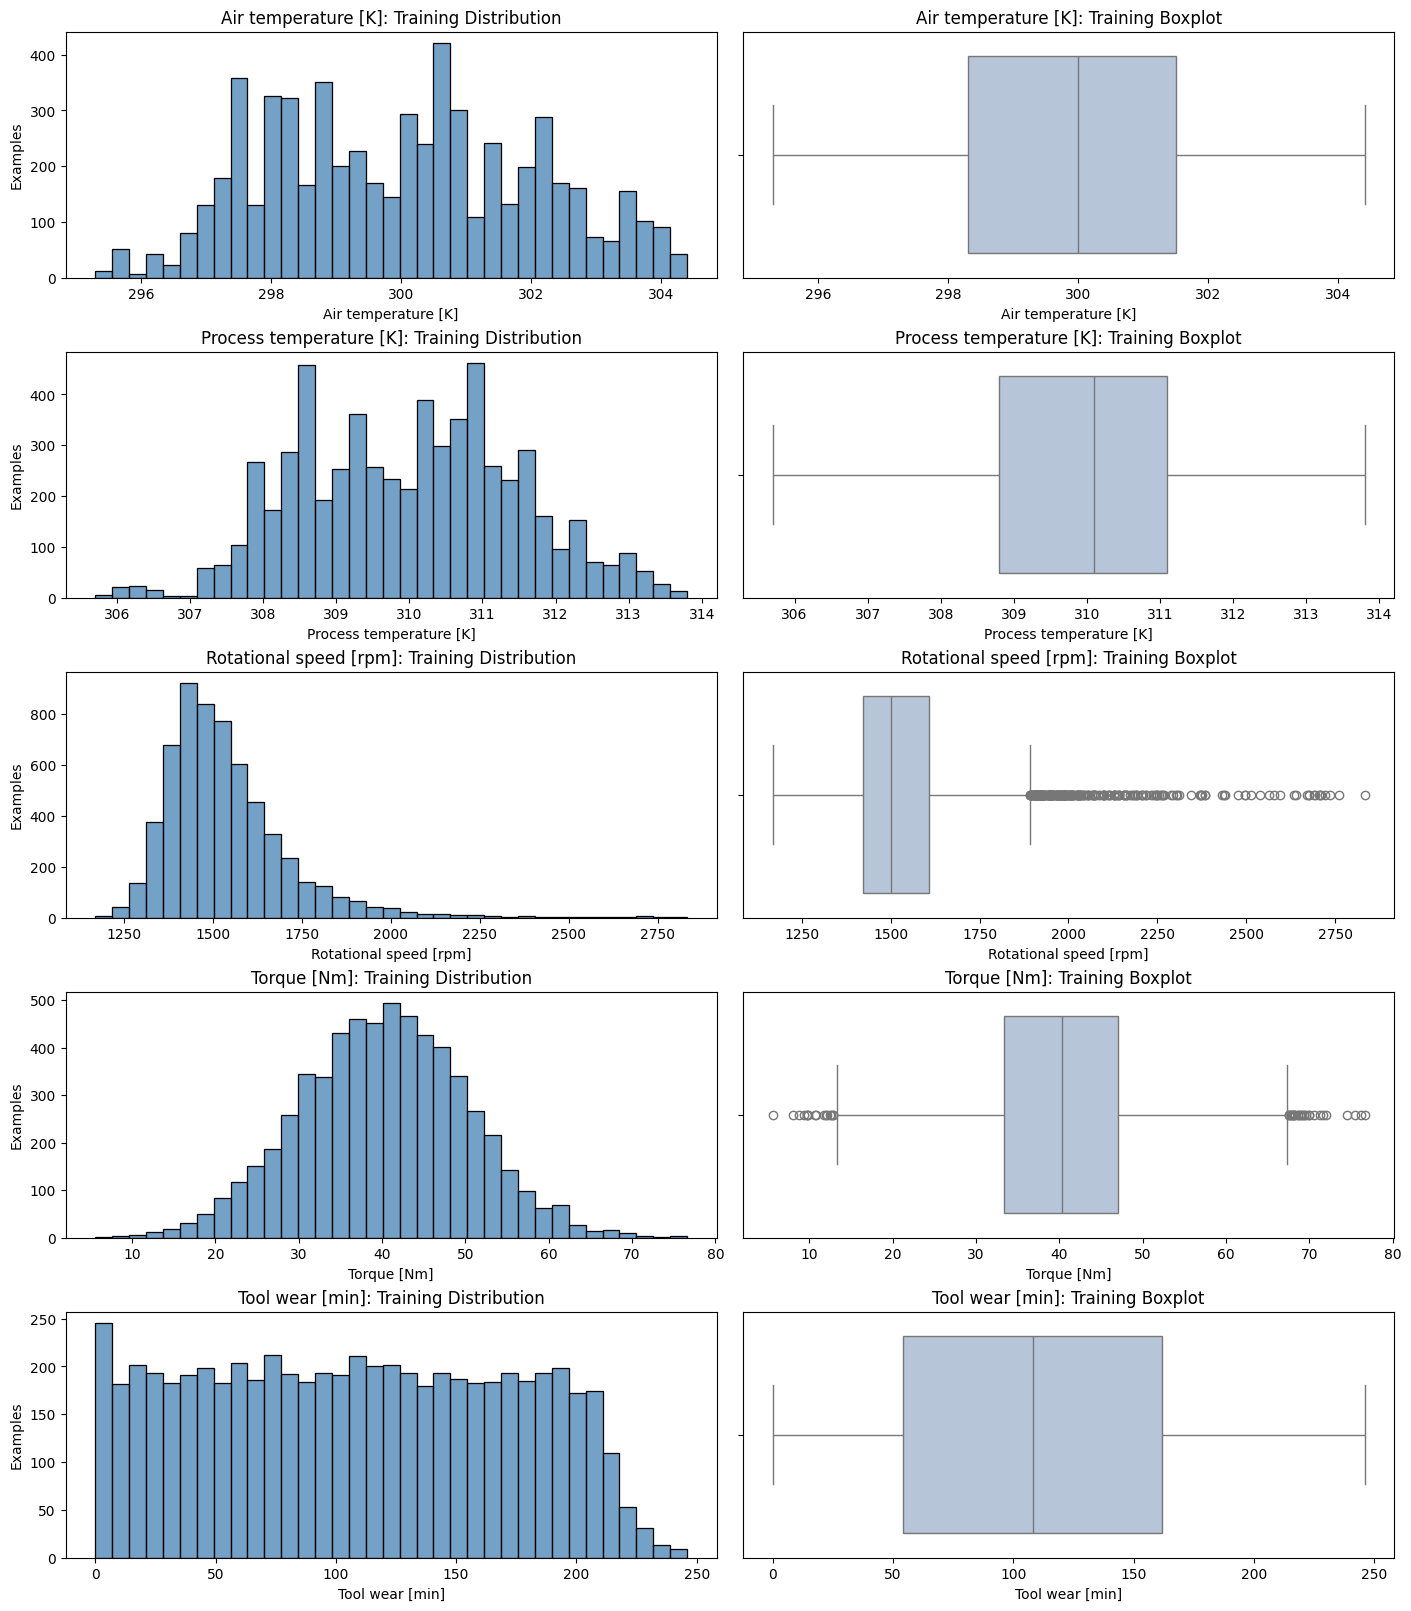

In [8]:
import seaborn as sns

numeric_summary = train[NUMERIC_FEATURES].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

display(numeric_summary.round(3))

numeric_summary.to_csv(
    RESULTS_DIR / "maintenance_training_numeric_summary.csv"
)

fig, axes = plt.subplots(
    len(NUMERIC_FEATURES),
    2,
    figsize=(14, 16),
    constrained_layout=True,
)

for row, feature in enumerate(NUMERIC_FEATURES):
    sns.histplot(
        data=train,
        x=feature,
        bins=35,
        color="steelblue",
        ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{feature}: Training Distribution")
    axes[row, 0].set_ylabel("Examples")

    sns.boxplot(
        data=train,
        x=feature,
        color="lightsteelblue",
        ax=axes[row, 1],
    )
    axes[row, 1].set_title(f"{feature}: Training Boxplot")

fig.savefig(
    PLOT_DIR / "maintenance_training_numeric_distributions.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

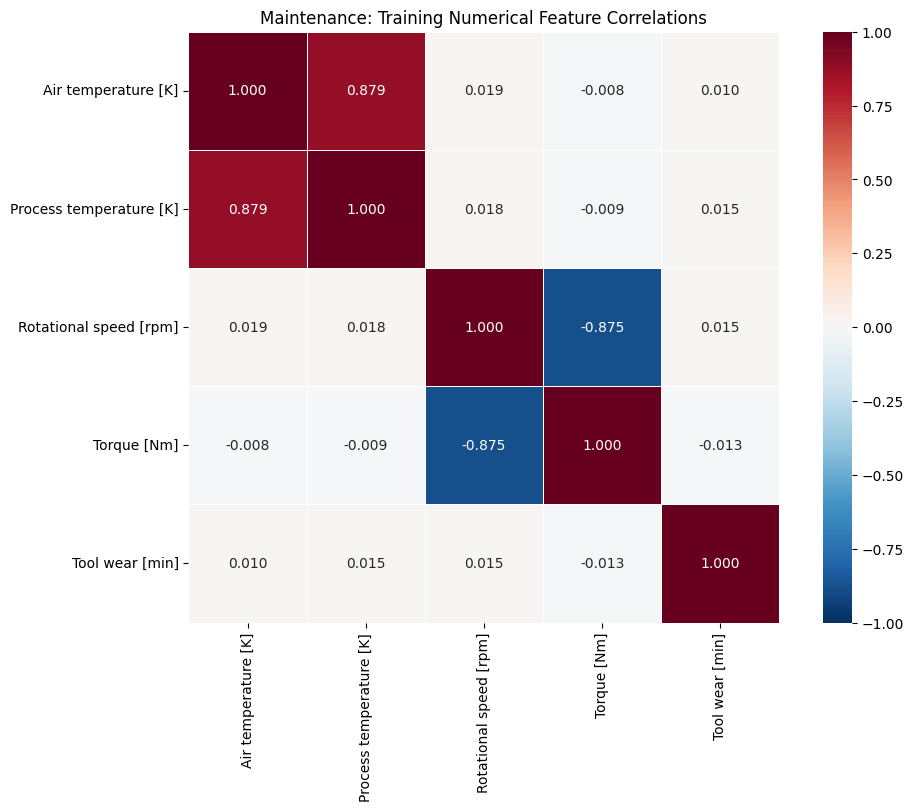

In [9]:
feature_correlations = train[NUMERIC_FEATURES].corr()

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

sns.heatmap(
    feature_correlations,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Maintenance: Training Numerical Feature Correlations")

fig.savefig(
    PLOT_DIR / "maintenance_training_correlations.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

feature_correlations.to_csv(
    RESULTS_DIR / "maintenance_training_correlations.csv"
)

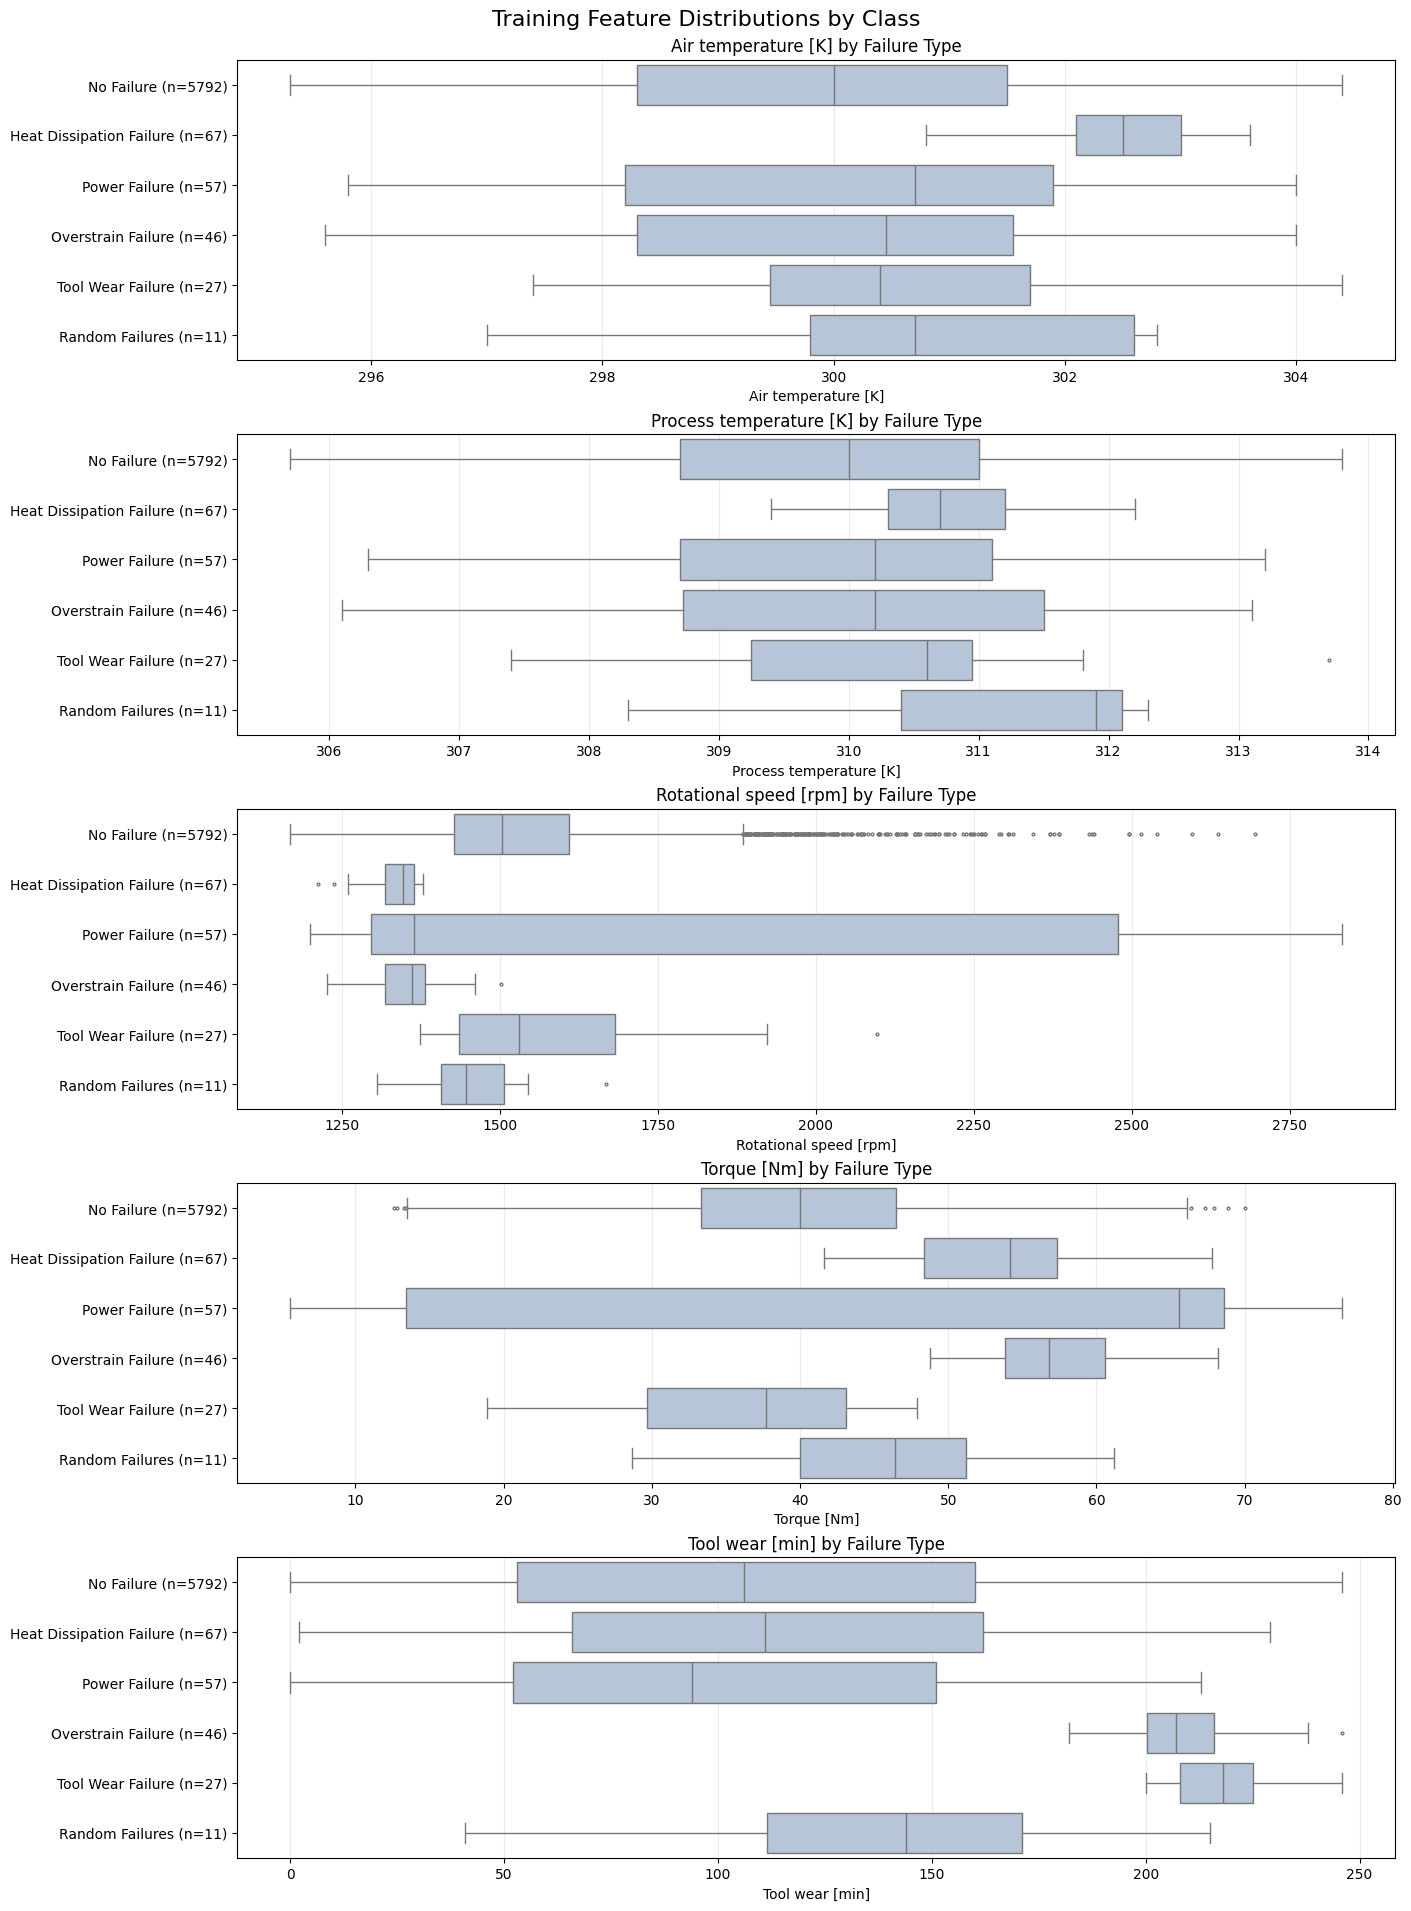

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Failure Type,,,,,
No Failure,300.00,310.0,1504.0,40.0,106.0
Heat Dissipation Failure,302.50,310.7,1346.0,54.2,111.0
Power Failure,300.70,310.2,1364.0,65.6,94.0
Overstrain Failure,300.45,310.2,1360.5,56.8,207.0
Tool Wear Failure,300.40,310.6,1530.0,37.7,218.0
Random Failures,300.70,311.9,1447.0,46.4,144.0


In [10]:
class_order = train[TARGET].value_counts().index.tolist()
class_labels = [
    f"{name} (n={int((train[TARGET] == name).sum())})"
    for name in class_order
]

fig, axes = plt.subplots(
    len(NUMERIC_FEATURES),
    1,
    figsize=(14, 19),
    constrained_layout=True,
)

for ax, feature in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(
        data=train,
        x=feature,
        y=TARGET,
        order=class_order,
        color="lightsteelblue",
        fliersize=2,
        ax=ax,
    )

    ax.set_yticks(range(len(class_order)))
    ax.set_yticklabels(class_labels)
    ax.set_ylabel("")
    ax.set_title(f"{feature} by Failure Type")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Training Feature Distributions by Class",
    fontsize=16,
)

fig.savefig(
    PLOT_DIR / "maintenance_training_features_by_class.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

class_medians = (
    train.groupby(TARGET)[NUMERIC_FEATURES]
    .median()
    .reindex(class_order)
)

display(class_medians.round(3))

class_medians.to_csv(
    RESULTS_DIR / "maintenance_training_class_medians.csv"
)

TRAINING CLASS COUNTS BY PRODUCT TYPE


Failure Type,No Failure,Heat Dissipation Failure,Power Failure,Overstrain Failure,Tool Wear Failure,Random Failures
Type,,,,,,
L,3473,43,34,41,15,9
M,1742,19,19,4,8,1
H,577,5,4,1,4,1


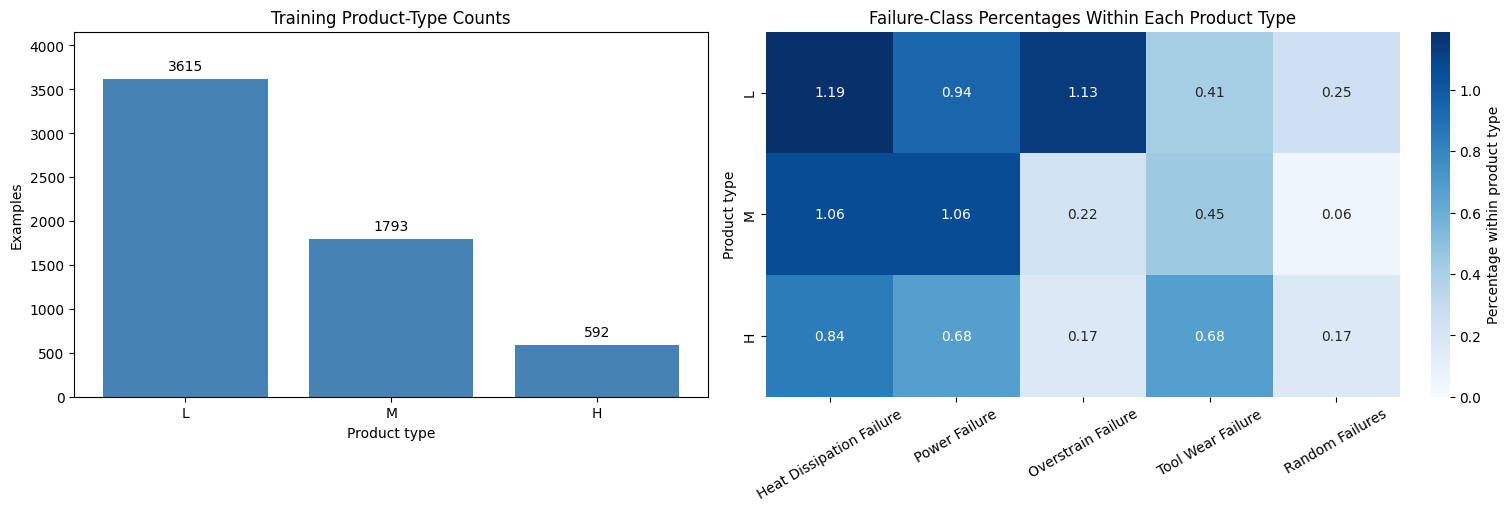

In [11]:
type_class_counts = pd.crosstab(
    train["Type"],
    train[TARGET],
).reindex(
    index=["L", "M", "H"],
    columns=class_order,
    fill_value=0,
)

type_class_percentages = (
    type_class_counts
    .div(type_class_counts.sum(axis=1), axis=0)
    .mul(100)
)

print("TRAINING CLASS COUNTS BY PRODUCT TYPE")
display(type_class_counts)

failure_columns = [
    name for name in class_order if name != "No Failure"
]

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), constrained_layout=True
)

type_counts = type_class_counts.sum(axis=1)

bars = axes[0].bar(
    type_counts.index,
    type_counts.values,
    color="steelblue",
)
axes[0].bar_label(bars, padding=4)
axes[0].set_ylim(0, type_counts.max() * 1.15)
axes[0].set_title("Training Product-Type Counts")
axes[0].set_xlabel("Product type")
axes[0].set_ylabel("Examples")

sns.heatmap(
    type_class_percentages[failure_columns],
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    cbar_kws={"label": "Percentage within product type"},
    ax=axes[1],
)
axes[1].set_title("Failure-Class Percentages Within Each Product Type")
axes[1].set_xlabel("")
axes[1].set_ylabel("Product type")
axes[1].tick_params(axis="x", labelrotation=30)

fig.savefig(
    PLOT_DIR / "maintenance_training_product_types.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

type_class_counts.to_csv(
    RESULTS_DIR / "maintenance_training_type_class_counts.csv"
)
type_class_percentages.to_csv(
    RESULTS_DIR / "maintenance_training_type_class_percentages.csv"
)

## 5. Training-only preprocessing

Standardize five numerical features and one-hot encode product type using training data only, yielding eight inputs. Encode the six target classes as integer IDs.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=np.float32,
            ),
            CATEGORICAL_FEATURES,
        ),
    ],
    remainder="drop",
)

X_train = preprocessor.fit_transform(
    train[FEATURES]
).astype(np.float32)

X_val = preprocessor.transform(
    validation[FEATURES]
).astype(np.float32)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train[TARGET]).astype(np.int64)
y_val = label_encoder.transform(validation[TARGET]).astype(np.int64)

feature_names = preprocessor.get_feature_names_out()

label_mapping = pd.DataFrame({
    "class_id": np.arange(len(label_encoder.classes_)),
    "failure_type": label_encoder.classes_,
})

numeric_scaler = preprocessor.named_transformers_["numeric"]

assert int(numeric_scaler.n_samples_seen_) == len(train)
assert X_train.shape == (len(train), len(feature_names))
assert X_val.shape == (len(validation), len(feature_names))
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

np.testing.assert_allclose(
    X_train[:, :len(NUMERIC_FEATURES)].mean(axis=0),
    0,
    atol=1e-6,
)
np.testing.assert_allclose(
    X_train[:, :len(NUMERIC_FEATURES)].std(axis=0),
    1,
    atol=1e-5,
)

print("ENCODED FEATURES")
print(feature_names.tolist())

print("\nTARGET LABEL MAPPING")
display(label_mapping)

print("Training shapes:", X_train.shape, y_train.shape)
print("Validation shapes:", X_val.shape, y_val.shape)
print("Input dtype:", X_train.dtype)
print("Target dtype:", y_train.dtype)
print("PASS: preprocessing fitted on training data only.")

label_mapping.to_csv(
    RESULTS_DIR / "maintenance_label_mapping.csv",
    index=False,
)

ENCODED FEATURES
['numeric__Air temperature [K]', 'numeric__Process temperature [K]', 'numeric__Rotational speed [rpm]', 'numeric__Torque [Nm]', 'numeric__Tool wear [min]', 'categorical__Type_H', 'categorical__Type_L', 'categorical__Type_M']

TARGET LABEL MAPPING


,class_id,failure_type
0,0,Heat Dissipation Failure
1,1,No Failure
2,2,Overstrain Failure
3,3,Power Failure
4,4,Random Failures
5,5,Tool Wear Failure


Training shapes: (6000, 8) (6000,)
Validation shapes: (2000, 8) (2000,)
Input dtype: float32
Target dtype: int64
PASS: preprocessing fitted on training data only.


In [13]:
import json
from sklearn.model_selection import StratifiedKFold

classification_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED,
)

cv_class_rows = []

for fold, (fit_indices, score_indices) in enumerate(
    classification_cv.split(train[FEATURES], y_train),
    start=1,
):
    assert set(fit_indices).isdisjoint(score_indices)

    for partition, indices in [
        ("fit", fit_indices),
        ("score", score_indices),
    ]:
        counts = np.bincount(
            y_train[indices],
            minlength=len(label_encoder.classes_),
        )

        assert (counts > 0).all()

        cv_class_rows.append({
            "fold": fold,
            "partition": partition,
            **dict(zip(label_encoder.classes_, counts.tolist())),
        })

cv_class_support = pd.DataFrame(cv_class_rows)
display(cv_class_support.set_index(["fold", "partition"]))

preprocessing_config = {
    "target": TARGET,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "excluded_columns": EXCLUDED_COLUMNS,
    "encoded_features": feature_names.tolist(),
    "label_mapping": {
        name: int(index)
        for index, name in enumerate(label_encoder.classes_)
    },
    "split": {
        "method": "Two-stage stratified random split",
        "seed": SEED,
        "train_samples": len(train),
        "validation_samples": len(validation),
        "test_samples": len(test),
    },
    "numeric_scaling": {
        "fit_partition": "Original training data",
        "mean": numeric_scaler.mean_.tolist(),
        "scale": numeric_scaler.scale_.tolist(),
    },
    "categorical_encoding": {
        "method": "OneHotEncoder",
        "categories": (
            preprocessor.named_transformers_["categorical"]
            .categories_[0].tolist()
        ),
        "handle_unknown": "ignore",
    },
    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 3,
        "shuffle": True,
        "seed": SEED,
        "preprocessing": "Fit separately within each training fold",
        "resampling": "Training folds only, when enabled",
    },
    "label_disagreements": {
        "count": len(label_disagreements),
        "policy": "Keep supplied Failure Type labels and all rows",
    },
    "balancing_applied": False,
    "test_evaluated": False,
}

cv_class_support.to_csv(
    RESULTS_DIR / "maintenance_cv_class_support.csv",
    index=False,
)

(RESULTS_DIR / "maintenance_preprocessing_config.json").write_text(
    json.dumps(preprocessing_config, indent=2),
    encoding="utf-8",
)

print("PASS: all six classes occur in every CV fit and scoring partition.")
print("Saved CV class support and preprocessing configuration.")

Heat Dissipation Failure  No Failure  Overstrain Failure  \
fold partition                                                             
1    fit                              45        3861                  31   
     score                            22        1931                  15   
2    fit                              44        3861                  31   
     score                            23        1931                  15   
3    fit                              45        3862                  30   
     score                            22        1930                  16   

                Power Failure  Random Failures  Tool Wear Failure  
fold partition                                                     
1    fit                   38                7                 18  
     score                 19                4                  9  
2    fit                   38                8                 18  
     score                 19                3                  9  
3    fit                   38                7                 18  
     score                 19                4                  9

PASS: all six classes occur in every CV fit and scoring partition.
Saved CV class support and preprocessing configuration.


### Preprocessing and EDA conclusions

The maintenance dataset contains 10,000 rows and six failure-type
classes. No missing values, fully duplicated rows, repeated feature
combinations, or non-finite numerical values were found. Basic
physical-validity checks also passed.

Failure Type is the multiclass target. UDI and Product ID are excluded
as identifiers, and binary Target is excluded because it provides
outcome information.

There are 27 disagreements between binary Target and Failure Type:
18 Random Failures rows have Target = 0, and nine No Failure rows
have Target = 1. All rows and supplied Failure Type labels are retained;
the disagreement is documented rather than corrected without evidence.

### Partitions and imbalance

A stratified split with seed 42 produces 6,000 training, 2,000 validation,
and 2,000 test samples. All classes occur in every partition.
The split evaluates held-out records, not future-time forecasting.

No Failure accounts for 96.53% of training data. Random Failures has
only 11 training, three validation, and four test examples.
Accuracy alone is therefore insufficient; model comparisons will
prioritize macro-F1 and include per-class recall and F1.

Three-fold stratified CV retains every class in each partition.
However, Random Failures has only 3–4 examples per scoring fold,
so its estimated performance will be uncertain.

### Exploratory findings

- Air and process temperatures are positively correlated (r ≈ 0.879).
- Rotational speed and torque are negatively correlated (r ≈ −0.875).
- Rotational speed is right-skewed; extreme observations are retained.
- Heat Dissipation Failure has higher median air temperature and lower
  median rotational speed than No Failure.
- Overstrain Failure and Tool Wear Failure show higher tool wear.
- Product-type failure percentages differ, but some groups contain
  very few failure examples.

These are training-data associations, not causal conclusions.

### Preprocessing decisions

The five numerical features are standardized using training-only
statistics. Type is one-hot encoded, producing eight input features
in total. Failure Type is encoded as six integer class IDs.

Training inputs use float32 and targets use int64.
Validation uses the fitted training transformation unchanged.
During cross-validation, preprocessing will be fitted separately
within each training fold.

No balancing has been applied yet. The unbalanced baseline will be
compared with training-only oversampling. Validation and test class
distributions remain unchanged, and the test set remains unevaluated.

## 6. Unresampled baseline PyTorch MLP

Train an 8–32–16–6 ReLU MLP with unweighted cross-entropy, Adam (0.001), batch size 64, and 50 fixed epochs. Compare with the majority-class baseline. Validation macro-F1 is 0.500755, versus 0.163698 for the dummy; Random and Tool Wear failures have zero recall. The final epoch is retained.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_rows = []

for split, X, y in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
]:
    predictions = dummy_model.predict(X)

    dummy_rows.append({
        "model": "Majority-class baseline",
        "split": split,
        "accuracy": accuracy_score(y, predictions),
        "macro_recall": balanced_accuracy_score(y, predictions),
        "macro_f1": f1_score(
            y,
            predictions,
            labels=np.arange(len(label_encoder.classes_)),
            average="macro",
            zero_division=0,
        ),
    })

dummy_results = pd.DataFrame(dummy_rows)
display(dummy_results.round(6))

dummy_val_predictions = dummy_model.predict(X_val)

dummy_report = pd.DataFrame(
    classification_report(
        y_val,
        dummy_val_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

print("VALIDATION CLASSIFICATION REPORT")
display(dummy_report.round(4))

dummy_results.to_csv(
    RESULTS_DIR / "maintenance_dummy_metrics.csv",
    index=False,
)
dummy_report.to_csv(
    RESULTS_DIR / "maintenance_dummy_validation_report.csv"
)

print("Training data remain unresampled.")
print("Test set remains unevaluated.")

,model,split,accuracy,macro_recall,macro_f1
0,Majority-class baseline,train,0.965333,0.166667,0.163727
1,Majority-class baseline,validation,0.965000,0.166667,0.163698


VALIDATION CLASSIFICATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.0000,0.0000,0.0000,23.000
No Failure,0.9650,1.0000,0.9822,1930.000
Overstrain Failure,0.0000,0.0000,0.0000,16.000
Power Failure,0.0000,0.0000,0.0000,19.000
Random Failures,0.0000,0.0000,0.0000,3.000
Tool Wear Failure,0.0000,0.0000,0.0000,9.000
accuracy,0.9650,0.9650,0.9650,0.965
macro avg,0.1608,0.1667,0.1637,2000.000
weighted avg,0.9312,0.9650,0.9478,2000.000


Training data remain unresampled.
Test set remains unevaluated.


In [15]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


class MaintenanceMLP(nn.Module):
    def __init__(self, input_dim=8, num_classes=6):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, num_classes),
        )

    def forward(self, x):
        return self.network(x)


BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 50
NUM_CLASSES = len(label_encoder.classes_)

X_train_tensor = torch.from_numpy(X_train)
y_train_tensor = torch.from_numpy(y_train)
X_val_tensor = torch.from_numpy(X_val)
y_val_tensor = torch.from_numpy(y_val)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)

classification_model = MaintenanceMLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    classification_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0,
)

classification_model.eval()

with torch.no_grad():
    sample_logits = classification_model(
        X_train_tensor[:8].to(DEVICE)
    )
    sample_loss = criterion(
        sample_logits,
        y_train_tensor[:8].to(DEVICE),
    )

assert sample_logits.shape == (8, NUM_CLASSES)
assert torch.isfinite(sample_logits).all()
assert torch.isfinite(sample_loss)
assert y_train_tensor.dtype == torch.int64

print(classification_model)
print("Trainable parameters:", sum(
    p.numel()
    for p in classification_model.parameters()
    if p.requires_grad
))
print("Batches per epoch:", len(train_loader))
print("Output shape:", sample_logits.shape)
print("Device:", next(classification_model.parameters()).device)
print("PASS: forward pass and cross-entropy loss.")

MaintenanceMLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=6, bias=True)
  )
)
Trainable parameters: 918
Batches per epoch: 94
Output shape: torch.Size([8, 6])
Device: cuda:0
PASS: forward pass and cross-entropy loss.


In [16]:
X_train_device = X_train_tensor.to(DEVICE)
y_train_device = y_train_tensor.to(DEVICE)
X_val_device = X_val_tensor.to(DEVICE)
y_val_device = y_val_tensor.to(DEVICE)

classification_history_rows = []

for epoch in range(1, EPOCHS + 1):
    classification_model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = classification_model(X_batch)
        loss = criterion(logits, y_batch)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss at epoch {epoch}")

        loss.backward()
        optimizer.step()

    classification_model.eval()
    row = {"epoch": epoch}

    with torch.no_grad():
        for split, X, y in [
            ("train", X_train_device, y_train_device),
            ("validation", X_val_device, y_val_device),
        ]:
            logits = classification_model(X)
            predictions = logits.argmax(dim=1).cpu().numpy()
            actual = y.cpu().numpy()

            row[f"{split}_loss"] = criterion(logits, y).item()
            row[f"{split}_accuracy"] = accuracy_score(
                actual, predictions
            )
            row[f"{split}_macro_f1"] = f1_score(
                actual,
                predictions,
                labels=np.arange(NUM_CLASSES),
                average="macro",
                zero_division=0,
            )
            row[f"{split}_macro_recall"] = balanced_accuracy_score(
                actual, predictions
            )

    classification_history_rows.append(row)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:2d}/{EPOCHS} | "
            f"Loss: {row['train_loss']:.4f} / "
            f"{row['validation_loss']:.4f} | "
            f"Accuracy: {row['train_accuracy']:.4f} / "
            f"{row['validation_accuracy']:.4f} | "
            f"Macro-F1: {row['train_macro_f1']:.4f} / "
            f"{row['validation_macro_f1']:.4f}"
        )

classification_history = pd.DataFrame(classification_history_rows)

assert len(classification_history) == EPOCHS
assert np.isfinite(classification_history.to_numpy()).all()

classification_history.to_csv(
    RESULTS_DIR / "maintenance_baseline_training_history.csv",
    index=False,
)

print("\nPASS: training completed; history saved.")
print("Metric pairs are training / validation.")
print("Test set remains unevaluated.")

Epoch  1/50 | Loss: 0.6575 / 0.6686 | Accuracy: 0.9653 / 0.9650 | Macro-F1: 0.1637 / 0.1637
Epoch 10/50 | Loss: 0.1228 / 0.1239 | Accuracy: 0.9668 / 0.9660 | Macro-F1: 0.2147 / 0.1943
Epoch 20/50 | Loss: 0.0924 / 0.0956 | Accuracy: 0.9722 / 0.9680 | Macro-F1: 0.3306 / 0.3056
Epoch 30/50 | Loss: 0.0736 / 0.0789 | Accuracy: 0.9752 / 0.9750 | Macro-F1: 0.4273 / 0.4272
Epoch 40/50 | Loss: 0.0643 / 0.0726 | Accuracy: 0.9787 / 0.9765 | Macro-F1: 0.4892 / 0.4668
Epoch 50/50 | Loss: 0.0594 / 0.0675 | Accuracy: 0.9793 / 0.9800 | Macro-F1: 0.5038 / 0.5008

PASS: training completed; history saved.
Metric pairs are training / validation.
Test set remains unevaluated.


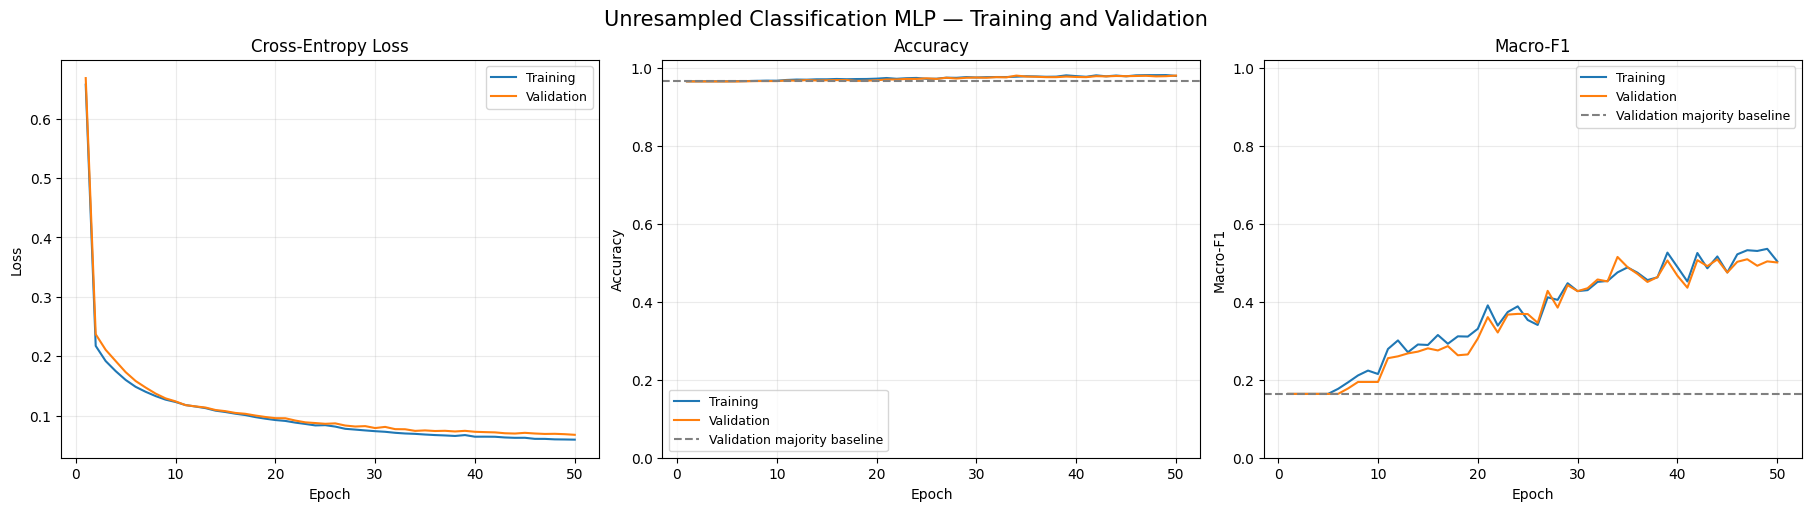

In [17]:
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), constrained_layout=True
)

plot_specs = [
    ("loss", "Cross-Entropy Loss", "Loss"),
    ("accuracy", "Accuracy", "Accuracy"),
    ("macro_f1", "Macro-F1", "Macro-F1"),
]

for ax, (metric, title, ylabel) in zip(axes, plot_specs):
    ax.plot(
        classification_history["epoch"],
        classification_history[f"train_{metric}"],
        label="Training",
    )
    ax.plot(
        classification_history["epoch"],
        classification_history[f"validation_{metric}"],
        label="Validation",
    )

    if metric in ["accuracy", "macro_f1"]:
        baseline_value = dummy_results.loc[
            dummy_results["split"].eq("validation"),
            metric,
        ].iloc[0]

        ax.axhline(
            baseline_value,
            color="gray",
            linestyle="--",
            label="Validation majority baseline",
        )
        ax.set_ylim(0, 1.02)

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    "Unresampled Classification MLP — Training and Validation",
    fontsize=15,
)

fig.savefig(
    PLOT_DIR / "maintenance_baseline_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

BASELINE VALIDATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.8571,0.5217,0.6486,23.00
No Failure,0.9822,0.9990,0.9905,1930.00
Overstrain Failure,0.8000,0.5000,0.6154,16.00
Power Failure,0.9231,0.6316,0.7500,19.00
Random Failures,0.0000,0.0000,0.0000,3.00
Tool Wear Failure,0.0000,0.0000,0.0000,9.00
accuracy,0.9800,0.9800,0.9800,0.98
macro avg,0.5937,0.4420,0.5008,2000.00
weighted avg,0.9728,0.9800,0.9753,2000.00


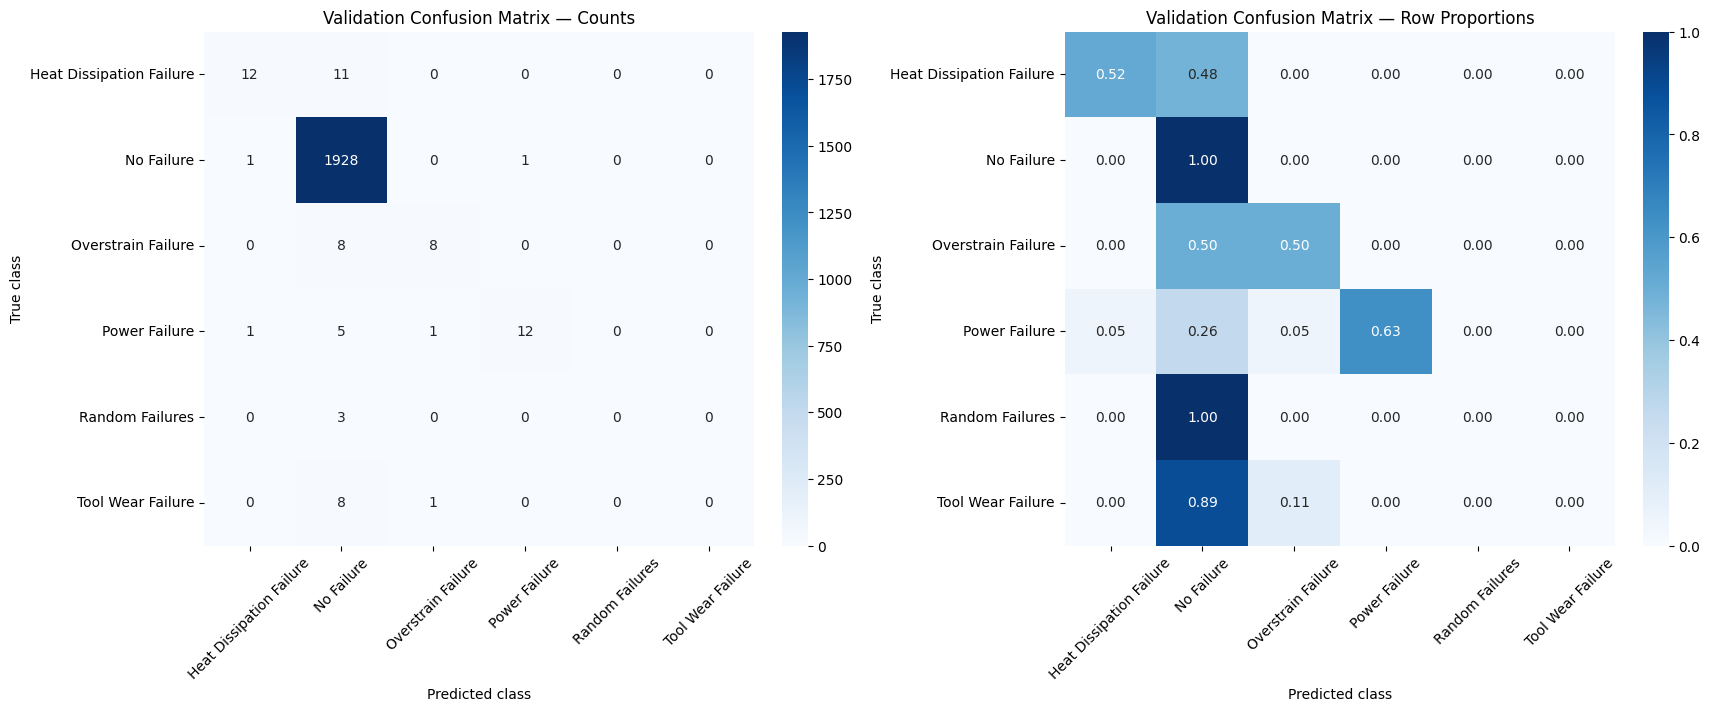

In [18]:
from sklearn.metrics import confusion_matrix

classification_model.eval()

with torch.no_grad():
    baseline_val_predictions = classification_model(
        X_val_device
    ).argmax(dim=1).cpu().numpy()

baseline_validation_report = pd.DataFrame(
    classification_report(
        y_val,
        baseline_val_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

print("BASELINE VALIDATION REPORT")
display(baseline_validation_report.round(4))

cm_counts = confusion_matrix(
    y_val,
    baseline_val_predictions,
    labels=np.arange(NUM_CLASSES),
)

cm_normalized = cm_counts / cm_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)

sns.heatmap(
    cm_counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[0],
)
axes[0].set_title("Validation Confusion Matrix — Counts")

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[1],
)
axes[1].set_title("Validation Confusion Matrix — Row Proportions")

for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

fig.savefig(
    PLOT_DIR / "maintenance_baseline_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

baseline_validation_report.to_csv(
    RESULTS_DIR / "maintenance_baseline_validation_report.csv"
)

pd.DataFrame(
    cm_counts,
    index=label_encoder.classes_,
    columns=label_encoder.classes_,
).rename_axis("true_class").to_csv(
    RESULTS_DIR / "maintenance_baseline_validation_confusion.csv"
)

baseline_prediction_table = pd.DataFrame({
    "UDI": maintenance.loc[validation.index, "UDI"].to_numpy(),
    "true_class": label_encoder.inverse_transform(y_val),
    "predicted_class": label_encoder.inverse_transform(
        baseline_val_predictions
    ),
})

baseline_prediction_table.to_csv(
    RESULTS_DIR / "maintenance_baseline_validation_predictions.csv",
    index=False,
)

In [19]:
baseline_classification_state = {
    key: value.detach().cpu().clone()
    for key, value in classification_model.state_dict().items()
}

final_baseline_epoch = classification_history.iloc[-1]

baseline_classification_metrics = pd.DataFrame([
    {
        "model": "Unresampled MLP",
        "split": split,
        **{
            metric: float(final_baseline_epoch[f"{split}_{metric}"])
            for metric in ["loss", "accuracy", "macro_recall", "macro_f1"]
        },
    }
    for split in ["train", "validation"]
])

np.testing.assert_allclose(
    baseline_classification_metrics.loc[
        baseline_classification_metrics["split"].eq("validation"),
        "macro_f1",
    ].iloc[0],
    baseline_validation_report.loc["macro avg", "f1-score"],
)

baseline_classification_config = {
    "seed": SEED,
    "input_features": feature_names.tolist(),
    "class_names": label_encoder.classes_.tolist(),
    "architecture": [X_train.shape[1], 32, 16, NUM_CLASSES],
    "hidden_activation": "ReLU",
    "output": "Raw logits",
    "loss": "Unweighted CrossEntropyLoss",
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "training_samples": len(y_train),
    "batches_per_epoch": len(train_loader),
    "optimizer_steps": EPOCHS * len(train_loader),
    "resampling": None,
    "selection": "Fixed final epoch",
    "preprocessing_fit_partition": "Original training data",
    "test_evaluated": False,
}

baseline_classification_metrics.to_csv(
    RESULTS_DIR / "maintenance_baseline_metrics.csv",
    index=False,
)

(RESULTS_DIR / "maintenance_baseline_config.json").write_text(
    json.dumps(baseline_classification_config, indent=2),
    encoding="utf-8",
)

display(baseline_classification_metrics.round(6))
print("PASS: baseline metrics agree with the classification report.")
print("Baseline weights preserved in memory.")

,model,split,loss,accuracy,macro_recall,macro_f1
0,Unresampled MLP,train,0.059357,0.979333,0.460983,0.503765
1,Unresampled MLP,validation,0.067498,0.980000,0.442047,0.500755


PASS: baseline metrics agree with the classification report.
Baseline weights preserved in memory.


## 7. Training-only oversampling comparison

Compare random oversampling with the unresampled baseline using the same architecture and 4,700 optimizer updates. Evaluate on original training and validation distributions. Select primarily by validation macro-F1.

In [20]:
from imblearn.over_sampling import RandomOverSampler

validation_snapshot = X_val.copy()
validation_labels_snapshot = y_val.copy()

oversampler = RandomOverSampler(
    sampling_strategy="not majority",
    random_state=SEED,
)

X_train_balanced, y_train_balanced = oversampler.fit_resample(
    X_train, y_train
)

before_counts = np.bincount(y_train, minlength=NUM_CLASSES)
after_counts = np.bincount(y_train_balanced, minlength=NUM_CLASSES)

balancing_summary = pd.DataFrame({
    "failure_type": label_encoder.classes_,
    "original_count": before_counts,
    "balanced_count": after_counts,
    "multiplication_factor": after_counts / before_counts,
})

np.testing.assert_array_equal(X_val, validation_snapshot)
np.testing.assert_array_equal(y_val, validation_labels_snapshot)

assert len(np.unique(after_counts)) == 1
assert len(np.unique(oversampler.sample_indices_)) == len(X_train)
assert np.isfinite(X_train_balanced).all()

display(balancing_summary.round(2))

print("Original training shape:", X_train.shape)
print("Balanced training shape:", X_train_balanced.shape)
print("Validation shape remains:", X_val.shape)
print("PASS: training-only resampling; all original samples retained.")

balancing_summary.to_csv(
    RESULTS_DIR / "maintenance_oversampling_summary.csv",
    index=False,
)

,failure_type,original_count,balanced_count,multiplication_factor
0,Heat Dissipation Failure,67,5792,86.45
1,No Failure,5792,5792,1.00
2,Overstrain Failure,46,5792,125.91
3,Power Failure,57,5792,101.61
4,Random Failures,11,5792,526.55
5,Tool Wear Failure,27,5792,214.52


Original training shape: (6000, 8)
Balanced training shape: (34752, 8)
Validation shape remains: (2000, 8)
PASS: training-only resampling; all original samples retained.


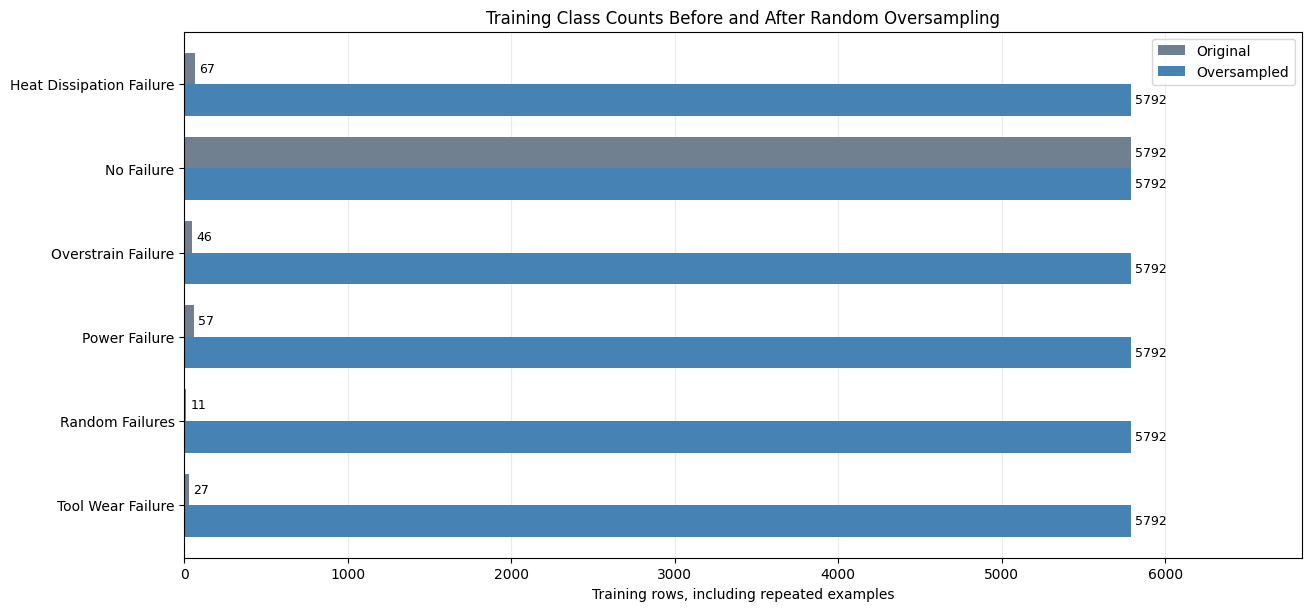

Baseline optimizer updates: 4700
Batches per full oversampled epoch: 543
Updates from 50 full oversampled epochs: 27150


In [21]:
plot_counts = balancing_summary.set_index("failure_type")[
    ["original_count", "balanced_count"]
]

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)

plot_counts.plot.barh(
    ax=ax,
    color=["slategray", "steelblue"],
    width=0.75,
)

ax.invert_yaxis()
ax.set_title("Training Class Counts Before and After Random Oversampling")
ax.set_xlabel("Training rows, including repeated examples")
ax.set_ylabel("")
ax.set_xlim(0, plot_counts.to_numpy().max() * 1.18)
ax.legend(["Original", "Oversampled"])
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

fig.savefig(
    PLOT_DIR / "maintenance_oversampling_class_counts.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

balanced_batches_per_epoch = (
    len(y_train_balanced) + BATCH_SIZE - 1
) // BATCH_SIZE

print("Baseline optimizer updates:",
      baseline_classification_config["optimizer_steps"])
print("Batches per full oversampled epoch:", balanced_batches_per_epoch)
print(
    "Updates from 50 full oversampled epochs:",
    50 * balanced_batches_per_epoch,
)

In [22]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

balanced_model = MaintenanceMLP(
    input_dim=X_train.shape[1],
    num_classes=NUM_CLASSES,
).to(DEVICE)

balanced_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_train_balanced.astype(np.float32)),
        torch.from_numpy(y_train_balanced.astype(np.int64)),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)

balanced_criterion = nn.CrossEntropyLoss()
balanced_optimizer = torch.optim.Adam(
    balanced_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0,
)

MAX_UPDATES = int(baseline_classification_config["optimizer_steps"])
EVALUATE_EVERY = int(
    baseline_classification_config["batches_per_epoch"]
)

assert MAX_UPDATES == 4700
assert EVALUATE_EVERY == 94
assert len(balanced_loader) == 543
assert balanced_model is not classification_model

balanced_model.eval()

with torch.no_grad():
    sample_logits = balanced_model(X_train_tensor[:8].to(DEVICE))

assert sample_logits.shape == (8, NUM_CLASSES)
assert torch.isfinite(sample_logits).all()

print("Optimizer-update budget:", MAX_UPDATES)
print("Evaluation interval:", EVALUATE_EVERY)
print("Evaluation points:", MAX_UPDATES // EVALUATE_EVERY)
print("Full oversampled epoch batches:", len(balanced_loader))
print("Updates for 50 full oversampled epochs:", 50 * len(balanced_loader))
print("PASS: fresh model ready; baseline model unchanged.")

Optimizer-update budget: 4700
Evaluation interval: 94
Evaluation points: 50
Full oversampled epoch batches: 543
Updates for 50 full oversampled epochs: 27150
PASS: fresh model ready; baseline model unchanged.


In [23]:
balanced_history_rows = []
updates = 0

while updates < MAX_UPDATES:
    balanced_model.train()

    for X_batch, y_batch in balanced_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        balanced_optimizer.zero_grad(set_to_none=True)
        logits = balanced_model(X_batch)
        loss = balanced_criterion(logits, y_batch)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at optimizer update {updates + 1}"
            )

        loss.backward()
        balanced_optimizer.step()
        updates += 1

        if updates % EVALUATE_EVERY == 0:
            balanced_model.eval()

            row = {
                "updates": updates,
                "evaluation_point": updates // EVALUATE_EVERY,
            }

            with torch.no_grad():
                for split, X, y in [
                    ("train", X_train_device, y_train_device),
                    ("validation", X_val_device, y_val_device),
                ]:
                    logits = balanced_model(X)
                    predictions = logits.argmax(dim=1).cpu().numpy()
                    actual = y.cpu().numpy()

                    row[f"{split}_loss"] = balanced_criterion(
                        logits, y
                    ).item()
                    row[f"{split}_accuracy"] = accuracy_score(
                        actual, predictions
                    )
                    row[f"{split}_macro_f1"] = f1_score(
                        actual,
                        predictions,
                        labels=np.arange(NUM_CLASSES),
                        average="macro",
                        zero_division=0,
                    )
                    row[f"{split}_macro_recall"] = (
                        balanced_accuracy_score(actual, predictions)
                    )

            assert all(np.isfinite(value) for value in row.values())
            balanced_history_rows.append(row)

            if row["evaluation_point"] == 1 or row["evaluation_point"] % 10 == 0:
                print(
                    f"Updates {updates:4d}/{MAX_UPDATES} | "
                    f"Validation loss: {row['validation_loss']:.4f} | "
                    f"Accuracy: {row['validation_accuracy']:.4f} | "
                    f"Macro-F1: {row['validation_macro_f1']:.4f} | "
                    f"Macro-recall: {row['validation_macro_recall']:.4f}"
                )

            balanced_model.train()

        if updates >= MAX_UPDATES:
            break

balanced_model.eval()
balanced_history = pd.DataFrame(balanced_history_rows)

assert updates == MAX_UPDATES
assert len(balanced_history) == 50
assert np.isfinite(balanced_history.to_numpy()).all()

balanced_history.to_csv(
    RESULTS_DIR / "maintenance_oversampled_training_history.csv",
    index=False,
)

print("\nPASS: completed exactly 4,700 optimizer updates.")
print("Training metrics use the original 6,000 training rows.")
print("Final-update model retained; no checkpoint selection.")
print("Test set remains unevaluated.")

Updates   94/4700 | Validation loss: 1.7673 | Accuracy: 0.1910 | Macro-F1: 0.1167 | Macro-recall: 0.5546
Updates  940/4700 | Validation loss: 0.6748 | Accuracy: 0.7125 | Macro-F1: 0.3654 | Macro-recall: 0.7107
Updates 1880/4700 | Validation loss: 0.5365 | Accuracy: 0.7875 | Macro-F1: 0.4327 | Macro-recall: 0.7317
Updates 2820/4700 | Validation loss: 0.4361 | Accuracy: 0.8410 | Macro-F1: 0.4502 | Macro-recall: 0.7225
Updates 3760/4700 | Validation loss: 0.3444 | Accuracy: 0.8825 | Macro-F1: 0.4693 | Macro-recall: 0.7297
Updates 4700/4700 | Validation loss: 0.3799 | Accuracy: 0.8785 | Macro-F1: 0.4827 | Macro-recall: 0.7290

PASS: completed exactly 4,700 optimizer updates.
Training metrics use the original 6,000 training rows.
Final-update model retained; no checkpoint selection.
Test set remains unevaluated.


OVERSAMPLED MODEL: VALIDATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.4894,1.0000,0.6571,23.0000
No Failure,0.9971,0.8793,0.9345,1930.0000
Overstrain Failure,0.3684,0.8750,0.5185,16.0000
Power Failure,0.5517,0.8421,0.6667,19.0000
Random Failures,0.0000,0.0000,0.0000,3.0000
Tool Wear Failure,0.0648,0.7778,0.1197,9.0000
accuracy,0.8785,0.8785,0.8785,0.8785
macro avg,0.4119,0.7290,0.4827,2000.0000
weighted avg,0.9763,0.8785,0.9203,2000.0000


PER-CLASS COMPARISON


,baseline_recall,oversampled_recall,baseline_f1,oversampled_f1,support
Heat Dissipation Failure,0.5217,1.0000,0.6486,0.6571,23.0
No Failure,0.9990,0.8793,0.9905,0.9345,1930.0
Overstrain Failure,0.5000,0.8750,0.6154,0.5185,16.0
Power Failure,0.6316,0.8421,0.7500,0.6667,19.0
Random Failures,0.0000,0.0000,0.0000,0.0000,3.0
Tool Wear Failure,0.0000,0.7778,0.0000,0.1197,9.0


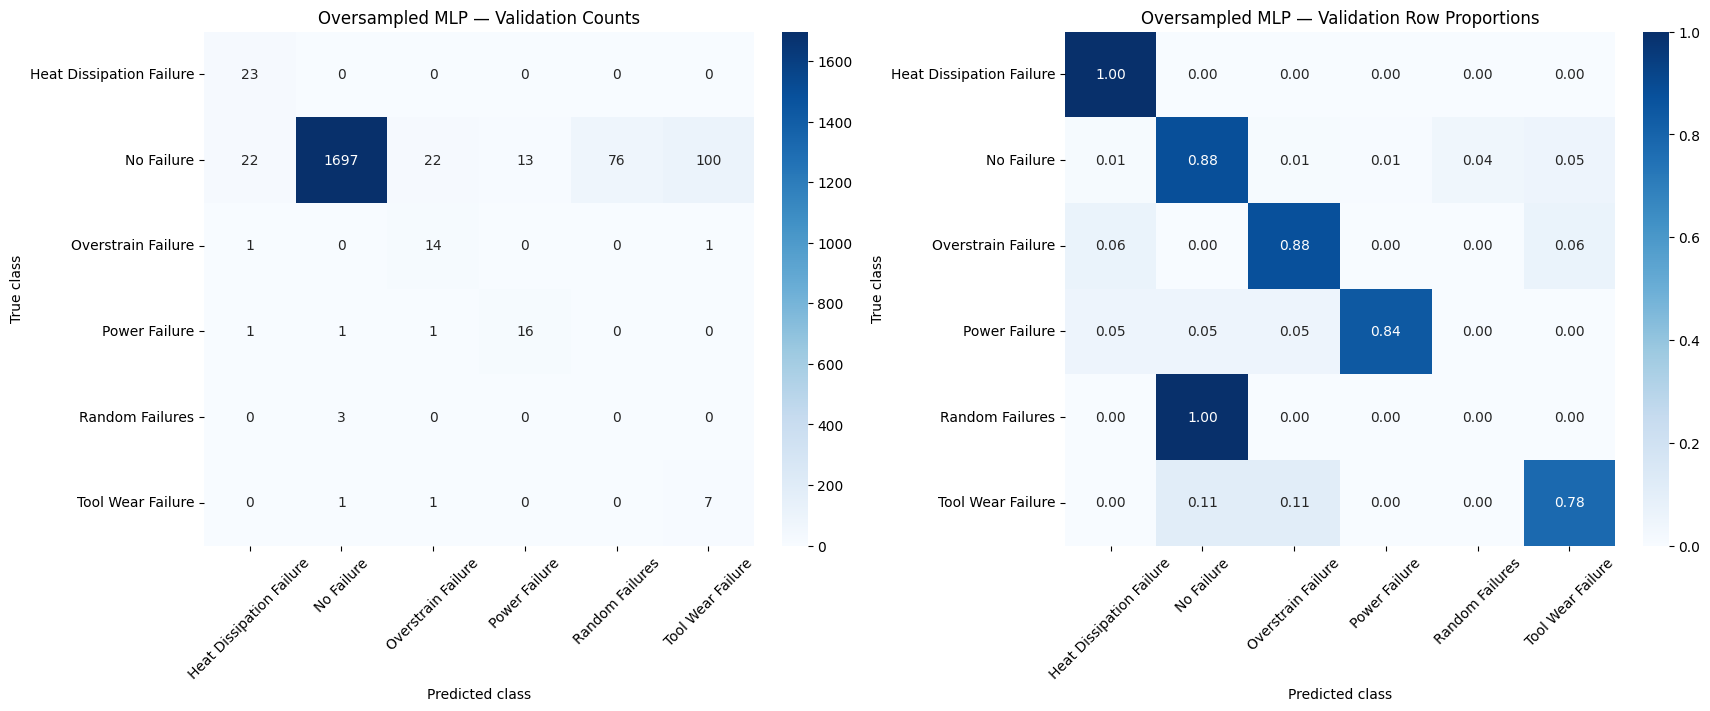

In [24]:
balanced_model.eval()

with torch.no_grad():
    balanced_val_predictions = balanced_model(
        X_val_device
    ).argmax(dim=1).cpu().numpy()

balanced_validation_report = pd.DataFrame(
    classification_report(
        y_val,
        balanced_val_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

print("OVERSAMPLED MODEL: VALIDATION REPORT")
display(balanced_validation_report.round(4))

per_class_comparison = pd.DataFrame({
    "baseline_recall": baseline_validation_report.loc[
        label_encoder.classes_, "recall"
    ],
    "oversampled_recall": balanced_validation_report.loc[
        label_encoder.classes_, "recall"
    ],
    "baseline_f1": baseline_validation_report.loc[
        label_encoder.classes_, "f1-score"
    ],
    "oversampled_f1": balanced_validation_report.loc[
        label_encoder.classes_, "f1-score"
    ],
    "support": balanced_validation_report.loc[
        label_encoder.classes_, "support"
    ],
})

print("PER-CLASS COMPARISON")
display(per_class_comparison.round(4))

balanced_cm = confusion_matrix(
    y_val,
    balanced_val_predictions,
    labels=np.arange(NUM_CLASSES),
)

balanced_cm_normalized = (
    balanced_cm / balanced_cm.sum(axis=1, keepdims=True)
)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)

for ax, values, fmt, title in [
    (axes[0], balanced_cm, "d", "Oversampled MLP — Validation Counts"),
    (
        axes[1],
        balanced_cm_normalized,
        ".2f",
        "Oversampled MLP — Validation Row Proportions",
    ),
]:
    sns.heatmap(
        values,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        vmin=0,
        vmax=1 if fmt == ".2f" else None,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

fig.savefig(
    PLOT_DIR / "maintenance_oversampled_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

balanced_validation_report.to_csv(
    RESULTS_DIR / "maintenance_oversampled_validation_report.csv"
)
per_class_comparison.to_csv(
    RESULTS_DIR / "maintenance_oversampling_per_class_comparison.csv"
)
pd.DataFrame(
    balanced_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_,
).rename_axis("true_class").to_csv(
    RESULTS_DIR / "maintenance_oversampled_validation_confusion.csv"
)

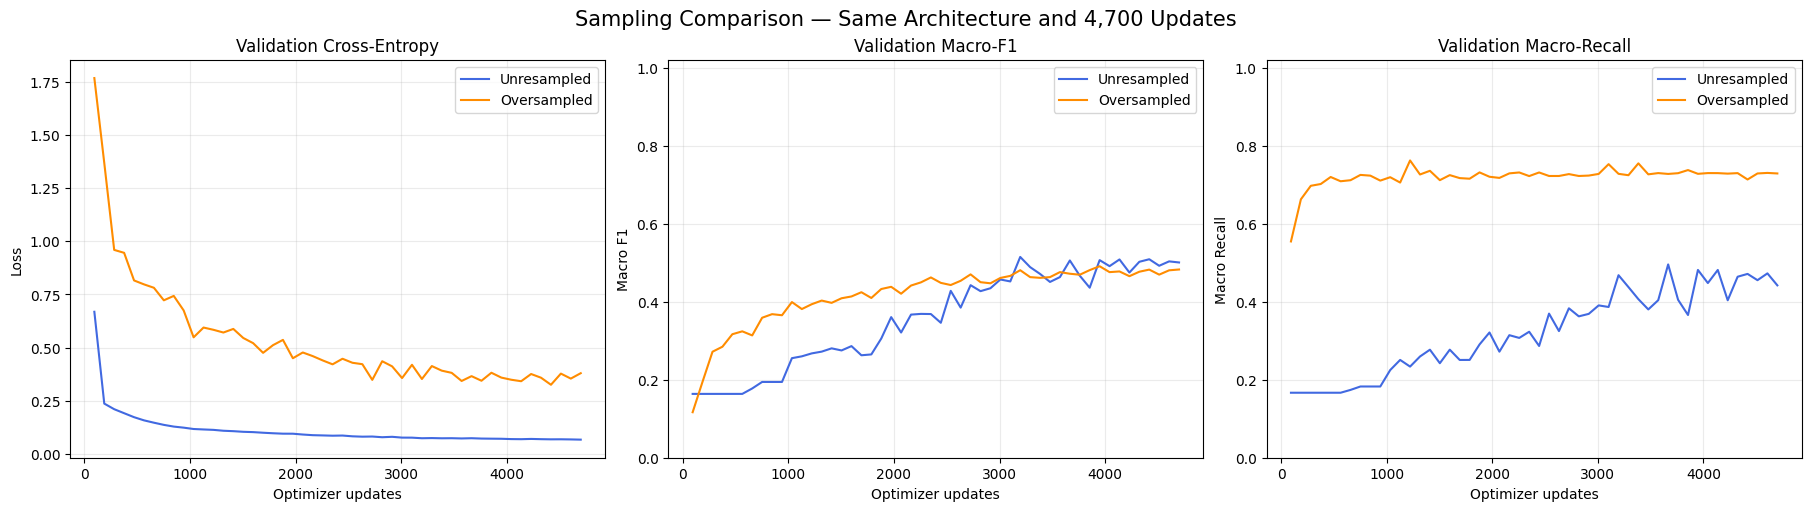

In [25]:
baseline_updates = (
    classification_history["epoch"]
    * baseline_classification_config["batches_per_epoch"]
)

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), constrained_layout=True
)

for ax, metric, title in zip(
    axes,
    ["loss", "macro_f1", "macro_recall"],
    ["Validation Cross-Entropy", "Validation Macro-F1", "Validation Macro-Recall"],
):
    ax.plot(
        baseline_updates,
        classification_history[f"validation_{metric}"],
        label="Unresampled",
        color="royalblue",
    )
    ax.plot(
        balanced_history["updates"],
        balanced_history[f"validation_{metric}"],
        label="Oversampled",
        color="darkorange",
    )

    ax.set_title(title)
    ax.set_xlabel("Optimizer updates")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.grid(alpha=0.25)
    ax.legend()

    if metric != "loss":
        ax.set_ylim(0, 1.02)

fig.suptitle(
    "Sampling Comparison — Same Architecture and 4,700 Updates",
    fontsize=15,
)

fig.savefig(
    PLOT_DIR / "maintenance_sampling_learning_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [26]:
final_balanced = balanced_history.iloc[-1]

oversampled_metrics = pd.DataFrame([
    {
        "model": "Oversampled MLP",
        "split": split,
        **{
            metric: float(final_balanced[f"{split}_{metric}"])
            for metric in ["loss", "accuracy", "macro_recall", "macro_f1"]
        },
    }
    for split in ["train", "validation"]
])

sampling_comparison = pd.concat(
    [baseline_classification_metrics, oversampled_metrics],
    ignore_index=True,
)

np.testing.assert_allclose(
    final_balanced["validation_macro_f1"],
    balanced_validation_report.loc["macro avg", "f1-score"],
)

balanced_prediction_table = pd.DataFrame({
    "UDI": maintenance.loc[validation.index, "UDI"].to_numpy(),
    "true_class": label_encoder.inverse_transform(y_val),
    "predicted_class": label_encoder.inverse_transform(
        balanced_val_predictions
    ),
})

oversampling_config = {
    "seed": SEED,
    "method": "RandomOverSampler",
    "sampling_strategy": "not majority",
    "original_training_samples": len(y_train),
    "resampled_training_samples": len(y_train_balanced),
    "class_counts": balancing_summary.to_dict(orient="records"),
    "architecture": [X_train.shape[1], 32, 16, NUM_CLASSES],
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "optimizer_updates": MAX_UPDATES,
    "evaluation_interval_updates": EVALUATE_EVERY,
    "selection": "Fixed final update; no checkpoint selection",
    "preprocessing_fit_partition": "Original training data",
    "training_metrics_partition": "Original unresampled training data",
    "validation_resampled": False,
    "test_evaluated": False,
    "primary_comparison_metric": "Validation macro-F1",
    "budget_note": (
        "Matched optimizer updates; final-batch sizes differ between loaders."
    ),
    "cv_policy": (
        "Fit preprocessing and resampling inside each training fold; "
        "never pass these globally oversampled arrays into cross-validation."
    ),
}

sampling_comparison.to_csv(
    RESULTS_DIR / "maintenance_sampling_comparison.csv",
    index=False,
)

balanced_prediction_table.to_csv(
    RESULTS_DIR / "maintenance_oversampled_validation_predictions.csv",
    index=False,
)

(RESULTS_DIR / "maintenance_oversampling_config.json").write_text(
    json.dumps(oversampling_config, indent=2),
    encoding="utf-8",
)

balanced_classification_state = {
    key: value.detach().cpu().clone()
    for key, value in balanced_model.state_dict().items()
}

display(sampling_comparison.round(6))

print("PASS: comparison, predictions, and configuration saved.")
print("Oversampled model weights preserved in memory.")
print("Test set remains unevaluated.")

,model,split,loss,accuracy,macro_recall,macro_f1
0,Unresampled MLP,train,0.059357,0.979333,0.460983,0.503765
1,Unresampled MLP,validation,0.067498,0.980000,0.442047,0.500755
2,Oversampled MLP,train,0.345770,0.880000,0.976823,0.509334
3,Oversampled MLP,validation,0.379919,0.878500,0.729026,0.482743


PASS: comparison, predictions, and configuration saved.
Oversampled model weights preserved in memory.
Test set remains unevaluated.


### Training-only oversampling comparison

RandomOverSampler increased each training class to 5,792 rows,
producing 34,752 training rows. All original samples were retained.
Oversampling repeated existing observations rather than generating
new information; Random Failures still had only 11 distinct originals.

Preprocessing was fitted on the original training data. Validation
and test data were not resampled.

Both MLPs used architecture 8–32–16–6, the same initialization seed,
Adam with learning rate 0.001, batch size 64, and 4,700 optimizer
updates. Final-batch sizes differed between loaders. No early stopping
or checkpoint selection was used.

All training metrics were computed on the original 6,000 training rows.

| Model | Validation accuracy | Macro-recall | Macro-F1 |
|---|---:|---:|---:|
| Unresampled MLP | 0.980000 | 0.442047 | 0.500755 |
| Oversampled MLP | 0.878500 | 0.729026 | 0.482743 |

Oversampling improved recall for Heat Dissipation, Overstrain, Power,
and Tool Wear failures. However, it increased false alarms: 233 of
1,930 No Failure examples were classified as failures, versus two
for the unresampled model.

Tool Wear recall improved from 0/9 to 7/9, but precision was only
6.48%. Random Failures remained undetected on validation (0/3).

Oversampled training macro-recall was 0.9768 compared with 0.7290
on validation, indicating a class-level generalization gap.
Minority-class estimates remain uncertain because supports are small.

Full oversampling did not improve the primary selection metric,
validation macro-F1. The unresampled model remains preferred under
this criterion for the current comparison.

Future cross-validation must fit preprocessing and any resampling
within each training fold. Globally oversampled arrays must not be
used as the input to cross-validation.

The test set remains unevaluated.

## 8. GridSearchCV with skorch and stratified folds

Three-fold GridSearchCV on original training rows, with fold-fitted preprocessing and macro-F1 selection. No oversampling is used.

In [27]:
from sklearn.model_selection import StratifiedKFold

X_search = train[FEATURES].copy()
y_search = label_encoder.transform(train[TARGET]).astype(np.int64)

search_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED,
)

search_folds = list(search_cv.split(X_search, y_search))
fold_rows = []

assert len(X_search) == 6000
assert X_search.index.is_unique
assert set(X_search.index).isdisjoint(validation.index)
assert set(X_search.index).isdisjoint(test.index)
assert not set(EXCLUDED_COLUMNS + [TARGET]).intersection(X_search.columns)

for fold, (fit_indices, score_indices) in enumerate(search_folds, start=1):
    assert set(fit_indices).isdisjoint(score_indices)
    assert len(fit_indices) + len(score_indices) == len(X_search)

    for partition, indices in [
        ("fit", fit_indices),
        ("score", score_indices),
    ]:
        counts = np.bincount(y_search[indices], minlength=NUM_CLASSES)
        assert (counts > 0).all()

        fold_rows.append({
            "fold": fold,
            "partition": partition,
            "samples": len(indices),
            **dict(zip(label_encoder.classes_, counts.tolist())),
        })

search_fold_support = pd.DataFrame(fold_rows)

display(search_fold_support.set_index(["fold", "partition"]))

search_fold_support.to_csv(
    RESULTS_DIR / "maintenance_gridsearch_fold_support.csv",
    index=False,
)

print("Raw search input shape:", X_search.shape)
print("Search target shape:", y_search.shape)
print("Selection metric: mean CV macro-F1 across all six classes.")
print("Preprocessing will be fitted separately within each fold.")
print("Resampling: disabled for this search.")
print("PASS: validation and test rows are excluded from CV.")

samples  Heat Dissipation Failure  No Failure  \
fold partition                                                  
1    fit           4000                        45        3861   
     score         2000                        22        1931   
2    fit           4000                        44        3861   
     score         2000                        23        1931   
3    fit           4000                        45        3862   
     score         2000                        22        1930   

                Overstrain Failure  Power Failure  Random Failures  \
fold partition                                                       
1    fit                        31             38                7   
     score                      15             19                4   
2    fit                        31             38                8   
     score                      15             19                3   
3    fit                        30             38                7   
     score                      16             19                4   

                Tool Wear Failure  
fold partition                     
1    fit                       18  
     score                      9  
2    fit                       18  
     score                      9  
3    fit                       18  
     score                      9

Raw search input shape: (6000, 6)
Search target shape: (6000,)
Selection metric: mean CV macro-F1 across all six classes.
Preprocessing will be fitted separately within each fold.
Resampling: disabled for this search.
PASS: validation and test rows are excluded from CV.


In [28]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from skorch import NeuralNetClassifier


class SearchMaintenanceMLP(nn.Module):
    def __init__(
        self,
        input_dim=8,
        hidden_sizes=(32, 16),
        num_classes=6,
    ):
        super().__init__()

        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_sizes:
            layers.extend([
                nn.Linear(previous_dim, hidden_dim),
                nn.ReLU(),
            ])
            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


class SeededMaintenanceClassifier(NeuralNetClassifier):
    def initialize(self):
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        return super().initialize()


def to_float32(values):
    return np.asarray(values, dtype=np.float32)


search_net = SeededMaintenanceClassifier(
    module=SearchMaintenanceMLP,
    module__input_dim=len(feature_names),
    module__hidden_sizes=(32, 16),
    module__num_classes=NUM_CLASSES,
    criterion=nn.CrossEntropyLoss,
    optimizer=torch.optim.Adam,
    optimizer__weight_decay=0.0,
    lr=0.001,
    max_epochs=50,
    batch_size=64,
    iterator_train__shuffle=True,
    iterator_train__num_workers=0,
    iterator_valid__num_workers=0,
    train_split=None,
    device=DEVICE,
    verbose=0,
)

search_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("float32", FunctionTransformer(to_float32, validate=False)),
    ("net", search_net),
])

assert not hasattr(
    search_pipeline.named_steps["preprocessor"],
    "transformers_",
)
assert search_pipeline.named_steps["net"].train_split is None

cloned_pipeline = clone(search_pipeline)
assert cloned_pipeline is not search_pipeline

print("Pipeline steps:", list(search_pipeline.named_steps))
print("Architecture: 8 → configurable hidden layers → 6 logits")
print("Loss: unweighted CrossEntropyLoss")
print("Batch size:", search_net.batch_size)
print("Internal validation split: disabled")
print("Early stopping: disabled")
print("Device:", DEVICE)
print("PASS: unfitted pipeline constructed and cloned successfully.")

Pipeline steps: ['preprocessor', 'float32', 'net']
Architecture: 8 → configurable hidden layers → 6 logits
Loss: unweighted CrossEntropyLoss
Batch size: 64
Internal validation split: disabled
Early stopping: disabled
Device: cuda
PASS: unfitted pipeline constructed and cloned successfully.


In [29]:
fit_indices, score_indices = search_folds[0]

smoke_pipeline = clone(search_pipeline).set_params(net__max_epochs=1)

smoke_pipeline.fit(
    X_search.iloc[fit_indices],
    y_search[fit_indices],
)

smoke_X = X_search.iloc[score_indices[:32]]
smoke_predictions = smoke_pipeline.predict(smoke_X)
smoke_probabilities = smoke_pipeline.predict_proba(smoke_X)

fitted_scaler = (
    smoke_pipeline.named_steps["preprocessor"]
    .named_transformers_["numeric"]
)

assert int(fitted_scaler.n_samples_seen_) == len(fit_indices)
assert smoke_predictions.shape == (32,)
assert smoke_probabilities.shape == (32, NUM_CLASSES)
assert np.isfinite(smoke_probabilities).all()
assert (smoke_probabilities >= 0).all()
assert (smoke_probabilities <= 1).all()
assert np.isin(smoke_predictions, np.arange(NUM_CLASSES)).all()

np.testing.assert_allclose(
    smoke_probabilities.sum(axis=1),
    1.0,
    atol=1e-6,
)

np.testing.assert_array_equal(
    smoke_predictions,
    smoke_probabilities.argmax(axis=1),
)

assert np.isfinite(
    smoke_pipeline.named_steps["net"].history[-1, "train_loss"]
)

print("Scaler fitting samples:", fitted_scaler.n_samples_seen_)
print("Prediction shape:", smoke_predictions.shape)
print("Probability shape:", smoke_probabilities.shape)
print(
    "Model device:",
    next(smoke_pipeline.named_steps["net"].module_.parameters()).device,
)
print("PASS: fold-only preprocessing, training, and predictions.")

del smoke_pipeline

Scaler fitting samples: 4000
Prediction shape: (32,)
Probability shape: (32, 6)
Model device: cuda:0
PASS: fold-only preprocessing, training, and predictions.


In [30]:
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import make_scorer

parameter_grid = {
    "net__lr": [0.001, 0.005],
    "net__optimizer": [torch.optim.Adam, torch.optim.RMSprop],
    "net__max_epochs": [50, 100],
    "net__module__hidden_sizes": [(32, 16), (64, 32, 16)],
}

macro_f1_scorer = make_scorer(
    f1_score,
    labels=np.arange(NUM_CLASSES),
    average="macro",
    zero_division=0,
)

classification_search = GridSearchCV(
    estimator=search_pipeline,
    param_grid=parameter_grid,
    scoring=macro_f1_scorer,
    cv=search_folds,
    refit=True,
    n_jobs=1,
    error_score="raise",
    return_train_score=False,
    verbose=2,
)

candidate_count = len(list(ParameterGrid(parameter_grid)))

print("Candidate configurations:", candidate_count)
print("CV folds:", len(search_folds))
print("CV training runs:", candidate_count * len(search_folds))
print("Final refits: 1")
print("Selection metric: mean CV macro-F1; higher is better.")
print("Preprocessing: fitted separately within each training fold.")
print("Resampling: disabled.")
print("Epoch budget: 50 or 100 complete training epochs per fit.")
print("Early stopping: disabled.")
print("Validation and test data are excluded from the search.")

Candidate configurations: 16
CV folds: 3
CV training runs: 48
Final refits: 1
Selection metric: mean CV macro-F1; higher is better.
Preprocessing: fitted separately within each training fold.
Resampling: disabled.
Epoch budget: 50 or 100 complete training epochs per fit.
Early stopping: disabled.
Validation and test data are excluded from the search.


In [31]:
from time import perf_counter

search_started = perf_counter()

classification_search.fit(X_search, y_search)

search_elapsed_seconds = perf_counter() - search_started

classification_cv_results = pd.DataFrame(
    classification_search.cv_results_
)

classification_ranking = pd.DataFrame({
    "rank": classification_cv_results["rank_test_score"],
    "learning_rate": classification_cv_results["param_net__lr"].astype(float),
    "optimizer": [
        optimizer.__name__
        for optimizer in classification_cv_results["param_net__optimizer"]
    ],
    "epochs": classification_cv_results["param_net__max_epochs"].astype(int),
    "hidden_layers": classification_cv_results[
        "param_net__module__hidden_sizes"
    ],
    "mean_cv_macro_f1": classification_cv_results["mean_test_score"],
    "std_cv_macro_f1": classification_cv_results["std_test_score"],
    "mean_fit_seconds": classification_cv_results["mean_fit_time"],
}).sort_values(
    ["rank", "mean_fit_seconds"]
).reset_index(drop=True)

assert len(classification_cv_results) == 16
assert np.isfinite(
    classification_cv_results[
        ["split0_test_score", "split1_test_score", "split2_test_score"]
    ].to_numpy()
).all()

best_index = classification_search.best_index_
best_fold_scores = np.array([
    classification_cv_results.loc[best_index, f"split{fold}_test_score"]
    for fold in range(len(search_folds))
])

np.testing.assert_allclose(
    best_fold_scores.mean(),
    classification_search.best_score_,
)

classification_cv_results.to_csv(
    RESULTS_DIR / "maintenance_gridsearch_cv_results.csv",
    index=False,
)

classification_ranking.to_csv(
    RESULTS_DIR / "maintenance_gridsearch_ranking.csv",
    index=False,
)

print(f"Search completed in {search_elapsed_seconds / 60:.2f} minutes.")
print("Best parameters:", classification_search.best_params_)
print(f"Best mean CV macro-F1: {classification_search.best_score_:.6f}")
print("Selected configuration's fold scores:", best_fold_scores.tolist())

display(classification_ranking)

print("PASS: search completed and CV results saved.")
print("Validation and test sets remain excluded from this search.")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END net__lr=0.001, net__max_epochs=50, net__module__hidden_sizes=(32, 16), net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   6.4s
[CV] END net__lr=0.001, net__max_epochs=50, net__module__hidden_sizes=(32, 16), net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   6.5s
[CV] END net__lr=0.001, net__max_epochs=50, net__module__hidden_sizes=(32, 16), net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   6.3s
[CV] END net__lr=0.001, net__max_epochs=50, net__module__hidden_sizes=(32, 16), net__optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   6.1s
[CV] END net__lr=0.001, net__max_epochs=50, net__module__hidden_sizes=(32, 16), net__optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   6.2s
[CV] END net__lr=0.001, net__max_epochs=50, net__module__hidden_sizes=(32, 16), net__optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   6.2s
[CV] END net__lr=0.001, net__max_epochs

,rank,learning_rate,optimizer,epochs,hidden_layers,mean_cv_macro_f1,std_cv_macro_f1,mean_fit_seconds
0,1,0.005,Adam,100,"(32, 16)",0.536721,0.038145,12.393692
1,2,0.005,RMSprop,100,"(32, 16)",0.526308,0.026089,12.066426
2,3,0.001,Adam,100,"(64, 32, 16)",0.522306,0.022848,13.580032
3,4,0.005,Adam,100,"(64, 32, 16)",0.515887,0.034394,13.525939
4,5,0.005,Adam,50,"(64, 32, 16)",0.513570,0.043167,6.708318
5,6,0.005,RMSprop,50,"(32, 16)",0.513397,0.022866,5.975757
6,7,0.001,Adam,100,"(32, 16)",0.508739,0.006566,12.573106
7,8,0.005,RMSprop,100,"(64, 32, 16)",0.499321,0.039606,13.245959
8,9,0.005,RMSprop,50,"(64, 32, 16)",0.498483,0.041391,6.596302
9,10,0.001,RMSprop,50,"(64, 32, 16)",0.494973,0.017051,6.746761


PASS: search completed and CV results saved.
Validation and test sets remain excluded from this search.


In [32]:
selected_classifier = classification_search.best_estimator_

selected_scaler = (
    selected_classifier.named_steps["preprocessor"]
    .named_transformers_["numeric"]
)

assert int(selected_scaler.n_samples_seen_) == len(train)
assert len(selected_classifier.named_steps["net"].history) == (
    classification_search.best_params_["net__max_epochs"]
)

selected_metric_rows = []

for split, X_raw, y_actual in [
    ("train", train[FEATURES], y_train),
    ("validation", validation[FEATURES], y_val),
]:
    predictions = selected_classifier.predict(X_raw)

    selected_metric_rows.append({
        "model": "CV-selected MLP",
        "split": split,
        "accuracy": accuracy_score(y_actual, predictions),
        "macro_recall": balanced_accuracy_score(y_actual, predictions),
        "macro_f1": f1_score(
            y_actual,
            predictions,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0,
        ),
    })

selected_classification_metrics = pd.DataFrame(selected_metric_rows)

comparison_columns = [
    "model", "split", "accuracy", "macro_recall", "macro_f1"
]

classification_tuning_comparison = pd.concat([
    dummy_results[comparison_columns],
    sampling_comparison[comparison_columns],
    selected_classification_metrics[comparison_columns],
], ignore_index=True)

selected_val_predictions = selected_classifier.predict(
    validation[FEATURES]
)

selected_prediction_table = pd.DataFrame({
    "UDI": maintenance.loc[validation.index, "UDI"].to_numpy(),
    "true_class": label_encoder.inverse_transform(y_val),
    "predicted_class": label_encoder.inverse_transform(
        selected_val_predictions
    ),
})

assert len(selected_prediction_table) == len(validation)
assert selected_prediction_table["UDI"].is_unique

classification_tuning_comparison.to_csv(
    RESULTS_DIR / "maintenance_tuning_comparison.csv",
    index=False,
)

selected_prediction_table.to_csv(
    RESULTS_DIR / "maintenance_tuned_validation_predictions.csv",
    index=False,
)

display(classification_tuning_comparison.round(6))

print("PASS: final refit preprocessing used 6,000 training rows only.")
print("Validation predictions and comparison saved.")
print("Test set remains unevaluated.")

,model,split,accuracy,macro_recall,macro_f1
0,Majority-class baseline,train,0.965333,0.166667,0.163727
1,Majority-class baseline,validation,0.965000,0.166667,0.163698
2,Unresampled MLP,train,0.979333,0.460983,0.503765
3,Unresampled MLP,validation,0.980000,0.442047,0.500755
4,Oversampled MLP,train,0.880000,0.976823,0.509334
5,Oversampled MLP,validation,0.878500,0.729026,0.482743
6,CV-selected MLP,train,0.985500,0.637810,0.623979
7,CV-selected MLP,validation,0.979500,0.575662,0.539219


PASS: final refit preprocessing used 6,000 training rows only.
Validation predictions and comparison saved.
Test set remains unevaluated.


CV-SELECTED MLP: VALIDATION REPORT


,precision,recall,f1-score,support
Heat Dissipation Failure,0.6216,1.0000,0.7667,23.0000
No Failure,0.9902,0.9902,0.9902,1930.0000
Overstrain Failure,0.7500,0.9375,0.8333,16.0000
Power Failure,0.8333,0.5263,0.6452,19.0000
Random Failures,0.0000,0.0000,0.0000,3.0000
Tool Wear Failure,0.0000,0.0000,0.0000,9.0000
accuracy,0.9795,0.9795,0.9795,0.9795
macro avg,0.5325,0.5757,0.5392,2000.0000
weighted avg,0.9766,0.9795,0.9771,2000.0000


PER-CLASS COMPARISON


,baseline_recall,tuned_recall,baseline_f1,tuned_f1,support
Heat Dissipation Failure,0.5217,1.0000,0.6486,0.7667,23.0
No Failure,0.9990,0.9902,0.9905,0.9902,1930.0
Overstrain Failure,0.5000,0.9375,0.6154,0.8333,16.0
Power Failure,0.6316,0.5263,0.7500,0.6452,19.0
Random Failures,0.0000,0.0000,0.0000,0.0000,3.0
Tool Wear Failure,0.0000,0.0000,0.0000,0.0000,9.0


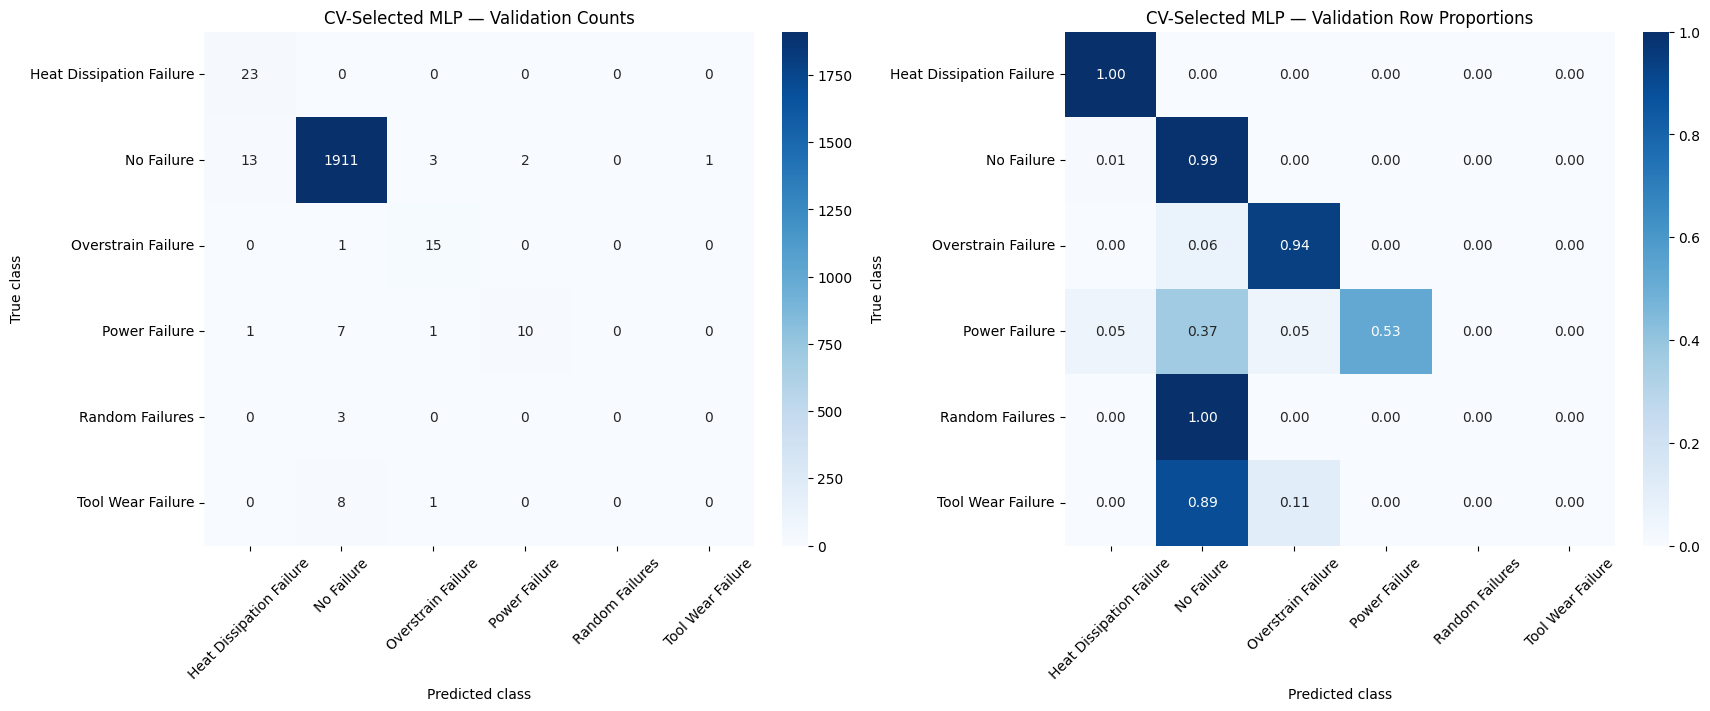

PASS: classification report matches the comparison metrics.


In [33]:
from sklearn.metrics import confusion_matrix

selected_validation_report = pd.DataFrame(
    classification_report(
        y_val,
        selected_val_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
).T

selected_per_class_comparison = pd.DataFrame({
    "baseline_recall": baseline_validation_report.loc[
        label_encoder.classes_, "recall"
    ],
    "tuned_recall": selected_validation_report.loc[
        label_encoder.classes_, "recall"
    ],
    "baseline_f1": baseline_validation_report.loc[
        label_encoder.classes_, "f1-score"
    ],
    "tuned_f1": selected_validation_report.loc[
        label_encoder.classes_, "f1-score"
    ],
    "support": selected_validation_report.loc[
        label_encoder.classes_, "support"
    ],
})

print("CV-SELECTED MLP: VALIDATION REPORT")
display(selected_validation_report.round(4))

print("PER-CLASS COMPARISON")
display(selected_per_class_comparison.round(4))

selected_cm = confusion_matrix(
    y_val,
    selected_val_predictions,
    labels=np.arange(NUM_CLASSES),
)

selected_cm_normalized = (
    selected_cm / selected_cm.sum(axis=1, keepdims=True)
)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)

for ax, values, fmt, title in [
    (axes[0], selected_cm, "d", "CV-Selected MLP — Validation Counts"),
    (
        axes[1],
        selected_cm_normalized,
        ".2f",
        "CV-Selected MLP — Validation Row Proportions",
    ),
]:
    sns.heatmap(
        values,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        vmin=0,
        vmax=1 if fmt == ".2f" else None,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

fig.savefig(
    PLOT_DIR / "maintenance_tuned_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

selected_validation_report.to_csv(
    RESULTS_DIR / "maintenance_tuned_validation_report.csv"
)

selected_per_class_comparison.to_csv(
    RESULTS_DIR / "maintenance_tuning_per_class_comparison.csv"
)

pd.DataFrame(
    selected_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_,
).rename_axis("true_class").to_csv(
    RESULTS_DIR / "maintenance_tuned_validation_confusion.csv"
)

np.testing.assert_allclose(
    selected_validation_report.loc["macro avg", "f1-score"],
    selected_classification_metrics.loc[
        selected_classification_metrics["split"].eq("validation"),
        "macro_f1",
    ].iloc[0],
)

print("PASS: classification report matches the comparison metrics.")

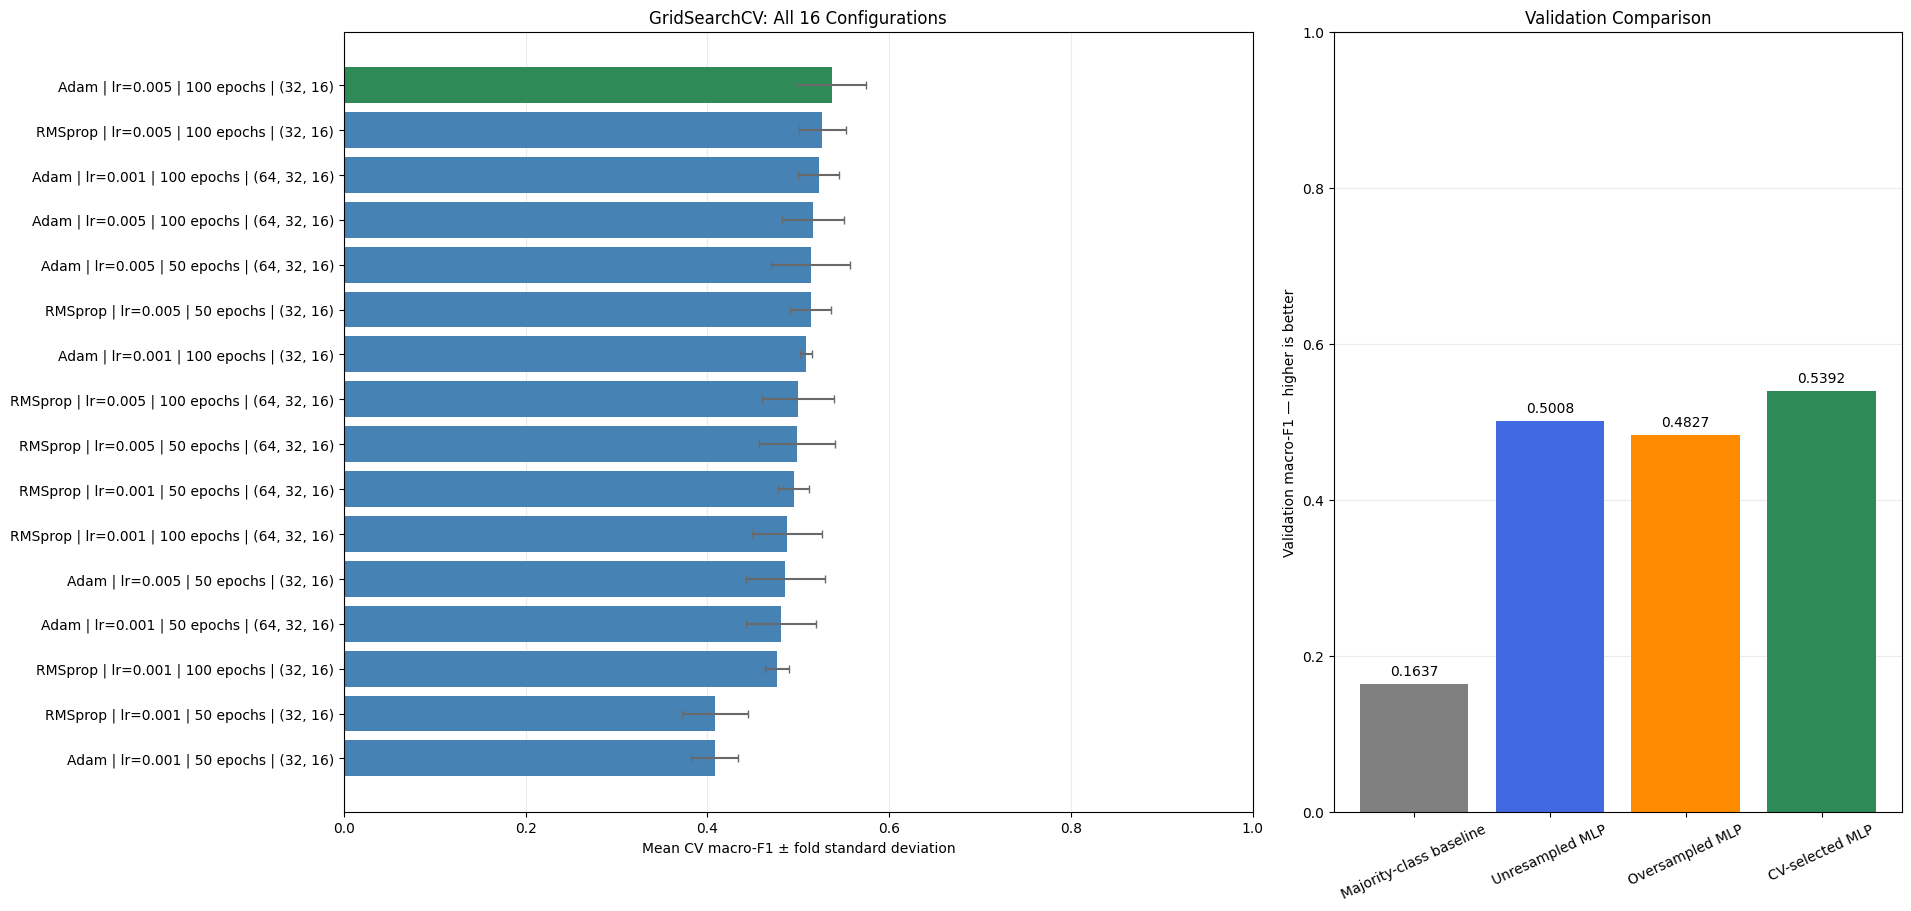

In [34]:
ranking_plot = classification_ranking.sort_values("rank").copy()

ranking_labels = [
    f"{row.optimizer} | lr={row.learning_rate:g} | "
    f"{row.epochs} epochs | {row.hidden_layers}"
    for row in ranking_plot.itertuples()
]

validation_plot = classification_tuning_comparison.loc[
    classification_tuning_comparison["split"].eq("validation")
].copy()

fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 9),
    gridspec_kw={"width_ratios": [1.6, 1]},
    constrained_layout=True,
)

positions = np.arange(len(ranking_plot))

axes[0].barh(
    positions,
    ranking_plot["mean_cv_macro_f1"],
    xerr=ranking_plot["std_cv_macro_f1"],
    color=[
        "seagreen" if rank == 1 else "steelblue"
        for rank in ranking_plot["rank"]
    ],
    error_kw={"ecolor": "dimgray", "capsize": 3},
)
axes[0].set_yticks(positions)
axes[0].set_yticklabels(ranking_labels)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Mean CV macro-F1 ± fold standard deviation")
axes[0].set_title("GridSearchCV: All 16 Configurations")
axes[0].grid(axis="x", alpha=0.25)
axes[0].set_axisbelow(True)

bars = axes[1].bar(
    validation_plot["model"],
    validation_plot["macro_f1"],
    color=["gray", "royalblue", "darkorange", "seagreen"],
)
axes[1].bar_label(bars, fmt="%.4f", padding=4)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Validation macro-F1 — higher is better")
axes[1].set_title("Validation Comparison")
axes[1].tick_params(axis="x", labelrotation=25)
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_axisbelow(True)

fig.savefig(
    PLOT_DIR / "maintenance_gridsearch_and_validation_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [35]:
best_parameters = classification_search.best_params_

selected_configuration = {
    "learning_rate": float(best_parameters["net__lr"]),
    "optimizer": best_parameters["net__optimizer"].__name__,
    "epochs": int(best_parameters["net__max_epochs"]),
    "hidden_layers": list(best_parameters["net__module__hidden_sizes"]),
    "batch_size": int(selected_classifier.named_steps["net"].batch_size),
}

classification_search_config = {
    "seed": SEED,
    "target": TARGET,
    "input_features": FEATURES,
    "encoded_features": feature_names.tolist(),
    "class_names": label_encoder.classes_.tolist(),
    "training_samples": len(X_search),
    "cv": {
        "method": "StratifiedKFold",
        "folds": len(search_folds),
        "shuffle": True,
        "seed": SEED,
        "scoring": "Macro-F1 across all six classes",
        "preprocessing": "Fitted separately within each training fold",
        "resampling": None,
    },
    "parameter_grid": {
        "learning_rate": parameter_grid["net__lr"],
        "optimizer": [
            optimizer.__name__
            for optimizer in parameter_grid["net__optimizer"]
        ],
        "epochs": parameter_grid["net__max_epochs"],
        "hidden_layers": [
            list(layers)
            for layers in parameter_grid["net__module__hidden_sizes"]
        ],
    },
    "candidate_count": candidate_count,
    "cv_training_runs": candidate_count * len(search_folds),
    "final_refits": 1,
    "best_configuration": selected_configuration,
    "best_mean_cv_macro_f1": float(classification_search.best_score_),
    "selected_fold_macro_f1": best_fold_scores.tolist(),
    "elapsed_seconds": float(search_elapsed_seconds),
    "final_refit_epochs": len(
        selected_classifier.named_steps["net"].history
    ),
    "selection": "Highest mean CV macro-F1; fixed final epoch",
    "validation_used_in_search": False,
    "test_evaluated": False,
}

selected_classification_state = {
    key: value.detach().cpu().clone()
    for key, value in (
        selected_classifier.named_steps["net"].module_.state_dict().items()
    )
}

config_path = RESULTS_DIR / "maintenance_gridsearch_config.json"
config_path.write_text(
    json.dumps(classification_search_config, indent=2),
    encoding="utf-8",
)

assert classification_search_config["final_refit_epochs"] == (
    selected_configuration["epochs"]
)

print("Best configuration:", selected_configuration)
print("Selected fold macro-F1:", best_fold_scores.tolist())
print("Final refit epochs:", classification_search_config["final_refit_epochs"])
print("Saved:", config_path)
print("Selected weights preserved in memory.")
print("Test set remains unevaluated.")

Best configuration: {'learning_rate': 0.005, 'optimizer': 'Adam', 'epochs': 100, 'hidden_layers': [32, 16], 'batch_size': 64}
Selected fold macro-F1: [0.487749622562605, 0.5807998480746668, 0.541612118019361]
Final refit epochs: 100
Saved: /kaggle/working/results/maintenance_gridsearch_config.json
Selected weights preserved in memory.
Test set remains unevaluated.


In [36]:
from skorch.callbacks import Callback

report_X_train = selected_classifier.named_steps["preprocessor"].transform(
    train[FEATURES]
).astype(np.float32)

report_X_val = selected_classifier.named_steps["preprocessor"].transform(
    validation[FEATURES]
).astype(np.float32)

original_selected_probabilities = selected_classifier.predict_proba(
    validation[FEATURES]
)


class ClassificationReportingHistory(Callback):
    def on_train_begin(self, net, **kwargs):
        self.rows = []

    def on_epoch_end(self, net, **kwargs):
        python_state = random.getstate()
        numpy_state = np.random.get_state()
        torch_state = torch.get_rng_state()
        cuda_states = (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        )
        was_training = net.module_.training

        try:
            net.module_.eval()
            row = {"epoch": len(net.history)}

            with torch.no_grad():
                for split, X, y in [
                    ("train", report_X_train, y_train),
                    ("validation", report_X_val, y_val),
                ]:
                    logits = net.module_(
                        torch.from_numpy(X).to(net.device)
                    )
                    targets = torch.from_numpy(y).to(net.device)
                    predictions = logits.argmax(dim=1).cpu().numpy()

                    row[f"{split}_loss"] = (
                        torch.nn.functional.cross_entropy(
                            logits, targets
                        ).item()
                    )
                    row[f"{split}_accuracy"] = accuracy_score(
                        y, predictions
                    )
                    row[f"{split}_macro_recall"] = (
                        balanced_accuracy_score(y, predictions)
                    )
                    row[f"{split}_macro_f1"] = f1_score(
                        y,
                        predictions,
                        labels=np.arange(NUM_CLASSES),
                        average="macro",
                        zero_division=0,
                    )

            self.rows.append(row)

        finally:
            random.setstate(python_state)
            np.random.set_state(numpy_state)
            torch.set_rng_state(torch_state)

            if cuda_states is not None:
                torch.cuda.set_rng_state_all(cuda_states)

            net.module_.train(was_training)


reporting_classifier = clone(selected_classifier).set_params(
    net__callbacks=[
        ("reporting_history", ClassificationReportingHistory())
    ]
)

reporting_classifier.fit(X_search, y_search)

reporting_callback = dict(
    reporting_classifier.named_steps["net"].callbacks_
)["reporting_history"]

selected_reporting_history = pd.DataFrame(reporting_callback.rows)

reporting_probabilities = reporting_classifier.predict_proba(
    validation[FEATURES]
)
reporting_predictions = reporting_classifier.predict(validation[FEATURES])

max_probability_difference = float(np.max(np.abs(
    reporting_probabilities - original_selected_probabilities
)))

assert len(selected_reporting_history) == selected_configuration["epochs"]
assert np.isfinite(selected_reporting_history.to_numpy()).all()

np.testing.assert_allclose(
    reporting_probabilities,
    original_selected_probabilities,
    rtol=1e-5,
    atol=1e-6,
)
np.testing.assert_array_equal(
    reporting_predictions,
    selected_val_predictions,
)

selected_reporting_history.to_csv(
    RESULTS_DIR / "maintenance_tuned_reporting_history.csv",
    index=False,
)

print("Reporting-run epochs:", len(selected_reporting_history))
print("Maximum probability difference:", max_probability_difference)
display(selected_reporting_history.tail())
print("PASS: reporting predictions match the original selected model.")
print("Original selected model preserved; test set remains unevaluated.")

Reporting-run epochs: 100
Maximum probability difference: 0.0


,epoch,train_loss,train_accuracy,train_macro_recall,train_macro_f1,validation_loss,validation_accuracy,validation_macro_recall,validation_macro_f1
95,96,0.038156,0.989333,0.621695,0.634181,0.084095,0.9855,0.553812,0.560378
96,97,0.042666,0.988167,0.634045,0.629067,0.081499,0.9850,0.602549,0.585342
97,98,0.038823,0.988000,0.611506,0.642351,0.080301,0.9835,0.553815,0.565896
98,99,0.046975,0.987333,0.578429,0.609389,0.088588,0.9830,0.533062,0.551608
99,100,0.042152,0.985500,0.637810,0.623979,0.083379,0.9795,0.575662,0.539219


PASS: reporting predictions match the original selected model.
Original selected model preserved; test set remains unevaluated.


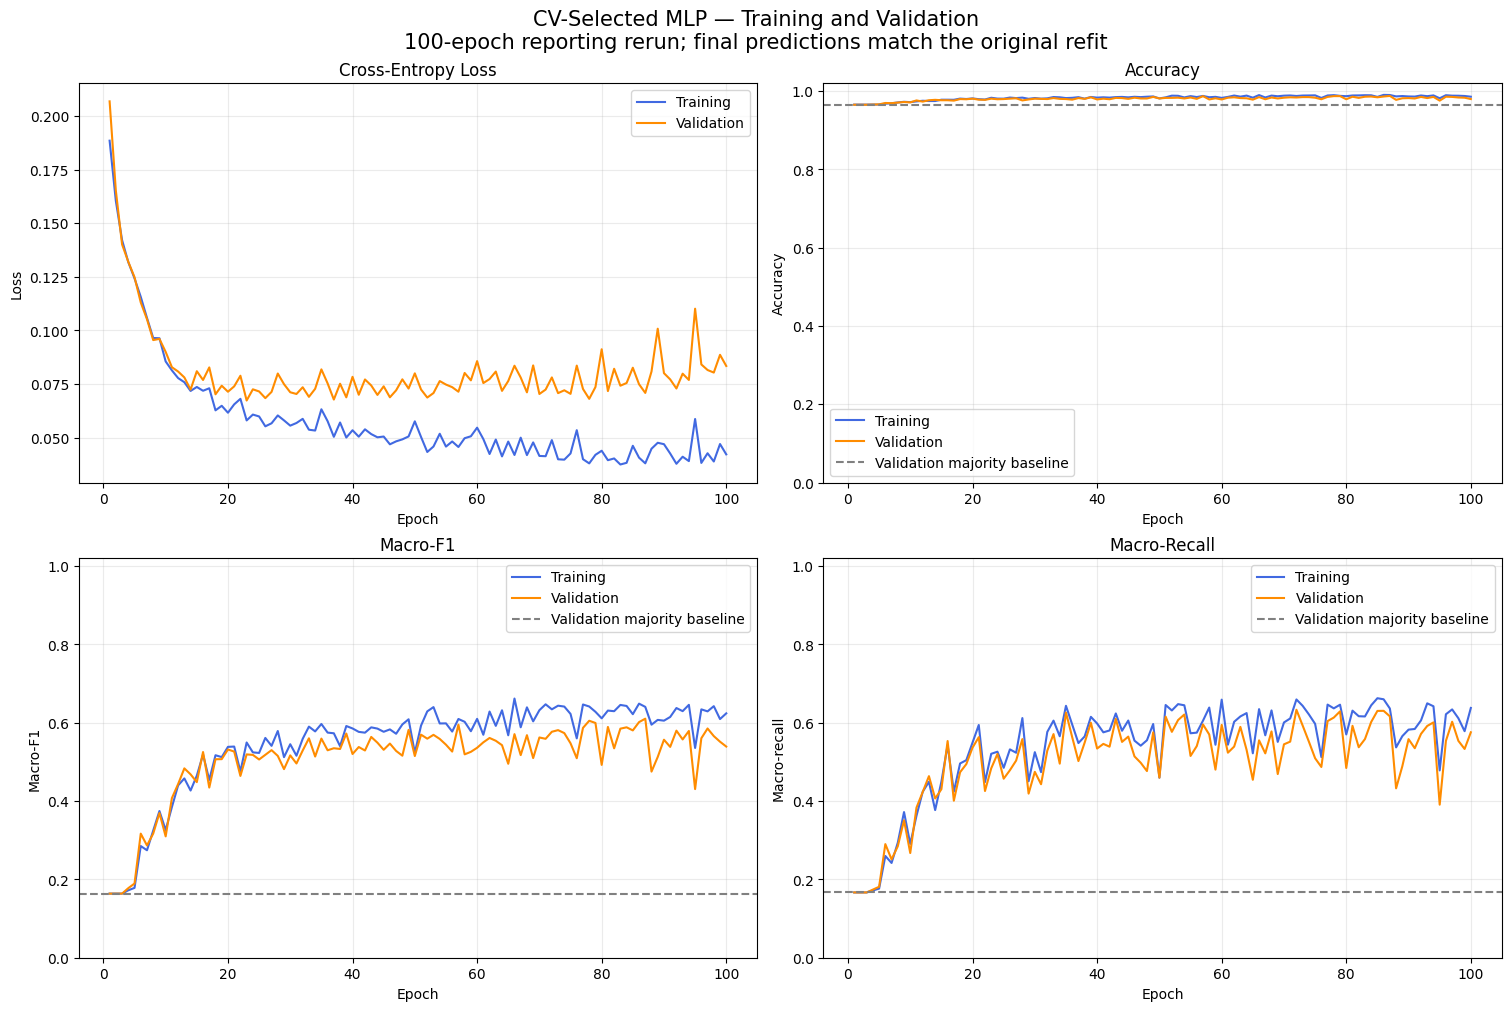

Saved learning curves and reporting-run provenance.


In [37]:
fig, axes = plt.subplots(
    2, 2, figsize=(15, 10), constrained_layout=True
)

plot_specs = [
    ("loss", "Cross-Entropy Loss", "Loss"),
    ("accuracy", "Accuracy", "Accuracy"),
    ("macro_f1", "Macro-F1", "Macro-F1"),
    ("macro_recall", "Macro-Recall", "Macro-recall"),
]

for ax, (metric, title, ylabel) in zip(axes.flat, plot_specs):
    ax.plot(
        selected_reporting_history["epoch"],
        selected_reporting_history[f"train_{metric}"],
        label="Training",
        color="royalblue",
    )
    ax.plot(
        selected_reporting_history["epoch"],
        selected_reporting_history[f"validation_{metric}"],
        label="Validation",
        color="darkorange",
    )

    if metric != "loss":
        dummy_value = dummy_results.loc[
            dummy_results["split"].eq("validation"),
            metric,
        ].iloc[0]

        ax.axhline(
            dummy_value,
            color="gray",
            linestyle="--",
            label="Validation majority baseline",
        )
        ax.set_ylim(0, 1.02)

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "CV-Selected MLP — Training and Validation\n"
    "100-epoch reporting rerun; final predictions match the original refit",
    fontsize=15,
)

fig.savefig(
    PLOT_DIR / "maintenance_tuned_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

classification_search_config["reporting_run"] = {
    "epochs": len(selected_reporting_history),
    "maximum_probability_difference": max_probability_difference,
    "predictions_match_original": True,
    "checkpoint_selection": False,
    "history_file": "maintenance_tuned_reporting_history.csv",
}

config_path.write_text(
    json.dumps(classification_search_config, indent=2),
    encoding="utf-8",
)

print("Saved learning curves and reporting-run provenance.")

### Hyperparameter tuning conclusions

GridSearchCV evaluated 16 configurations using three stratified folds
within the 6,000 training rows. Preprocessing was fitted separately
within each fold, and no oversampling was applied. Selection used
mean macro-F1 across all six classes.

The selected configuration uses hidden layers (32, 16), Adam with
learning rate 0.005, batch size 64, and 100 epochs. Mean CV macro-F1
was 0.536721, with fold scores 0.487750, 0.580800, and 0.541612.

After refitting on all training rows, validation macro-F1 was 0.539219,
compared with 0.500755 for the unresampled baseline and 0.482743 for
the oversampled model. Validation accuracy was 0.979500 and
macro-recall was 0.575662.

Improvements were concentrated in Heat Dissipation and Overstrain
failures: recall reached 23/23 and 15/16 respectively. Power Failure
recall declined from 12/19 to 10/19. Random Failures and Tool Wear
Failure still had zero recall. False alarms among No Failure records
increased from 2 to 19 out of 1,930.

A separate 100-epoch reporting rerun reproduced the selected model's
validation probabilities exactly. Training loss continued to decrease,
while validation loss plateaued and later fluctuated upward,
consistent with overfitting. Validation macro-F1 fluctuated after its
initial improvement. The original 100-epoch selection was retained;
the reporting curves were not used to select another checkpoint.

The tuned model is preferred among the current models by validation
macro-F1. Results remain limited to one seed and small minority-class
supports. Further regularization comparisons will use validation data;
the test set remains unevaluated.

## 9. Controlled regularization comparisons

Compare Reference, dropout, explicit L2, batch normalization, and validation-based early stopping under shared training settings.

In [38]:
regularization_settings = {
    "hidden_layers": tuple(selected_configuration["hidden_layers"]),
    "learning_rate": selected_configuration["learning_rate"],
    "optimizer": selected_configuration["optimizer"],
    "batch_size": selected_configuration["batch_size"],
    "max_epochs": selected_configuration["epochs"],
}

regularization_experiments = pd.DataFrame([
    {
        "name": "Reference",
        "dropout": 0.0,
        "l2_lambda": 0.0,
        "batch_norm": False,
        "early_stopping": False,
    },
    {
        "name": "Dropout",
        "dropout": 0.1,
        "l2_lambda": 0.0,
        "batch_norm": False,
        "early_stopping": False,
    },
    {
        "name": "L2",
        "dropout": 0.0,
        "l2_lambda": 1e-4,
        "batch_norm": False,
        "early_stopping": False,
    },
    {
        "name": "Batch normalization",
        "dropout": 0.0,
        "l2_lambda": 0.0,
        "batch_norm": True,
        "early_stopping": False,
    },
    {
        "name": "Early stopping",
        "dropout": 0.0,
        "l2_lambda": 0.0,
        "batch_norm": False,
        "early_stopping": True,
    },
]).set_index("name")

EARLY_STOPPING_PATIENCE = 15
EARLY_STOPPING_MIN_DELTA = 1e-4

assert regularization_settings["optimizer"] == "Adam"
assert regularization_settings["hidden_layers"] == (32, 16)
assert regularization_settings["max_epochs"] == 100
assert X_train.shape == (6000, 8)
assert X_val.shape == (2000, 8)

print("Shared settings:", regularization_settings)
display(regularization_experiments)

print("Training distribution: original, unresampled.")
print("Early-stopping metric: validation macro-F1; higher is better.")
print("Patience:", EARLY_STOPPING_PATIENCE)
print("Minimum improvement:", EARLY_STOPPING_MIN_DELTA)
print("Other variants retain their final epoch.")
print("Test data will not be used during these comparisons.")

Shared settings: {'hidden_layers': (32, 16), 'learning_rate': 0.005, 'optimizer': 'Adam', 'batch_size': 64, 'max_epochs': 100}


,dropout,l2_lambda,batch_norm,early_stopping
name,,,,
Reference,0.0,0.0000,False,False
Dropout,0.1,0.0000,False,False
L2,0.0,0.0001,False,False
Batch normalization,0.0,0.0000,True,False
Early stopping,0.0,0.0000,False,True


Training distribution: original, unresampled.
Early-stopping metric: validation macro-F1; higher is better.
Patience: 15
Minimum improvement: 0.0001
Other variants retain their final epoch.
Test data will not be used during these comparisons.


In [39]:
class RegularizedMaintenanceMLP(nn.Module):
    def __init__(
        self,
        input_dim=8,
        hidden_sizes=(32, 16),
        num_classes=6,
        dropout=0.0,
        batch_norm=False,
    ):
        super().__init__()

        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_sizes:
            layers.append(nn.Linear(previous_dim, hidden_dim))

            if batch_norm:
                layers.append(nn.BatchNorm1d(hidden_dim))

            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def linear_weight_penalty(model):
    return sum(
        layer.weight.square().sum()
        for layer in model.modules()
        if isinstance(layer, nn.Linear)
    )


variant_checks = []

for name, settings in regularization_experiments.iterrows():
    check_model = RegularizedMaintenanceMLP(
        input_dim=X_train.shape[1],
        hidden_sizes=regularization_settings["hidden_layers"],
        num_classes=NUM_CLASSES,
        dropout=float(settings["dropout"]),
        batch_norm=bool(settings["batch_norm"]),
    ).to(DEVICE)

    check_model.eval()

    with torch.no_grad():
        check_logits = check_model(
            torch.from_numpy(X_train[:8]).to(DEVICE)
        )
        check_loss = nn.functional.cross_entropy(
            check_logits,
            torch.from_numpy(y_train[:8]).to(DEVICE),
        )
        check_penalty = linear_weight_penalty(check_model)

    assert check_logits.shape == (8, NUM_CLASSES)
    assert torch.isfinite(check_logits).all()
    assert torch.isfinite(check_loss)
    assert torch.isfinite(check_penalty)
    assert check_penalty.item() >= 0

    variant_checks.append({
        "experiment": name,
        "trainable_parameters": sum(
            parameter.numel()
            for parameter in check_model.parameters()
            if parameter.requires_grad
        ),
        "output_shape": tuple(check_logits.shape),
    })

    del check_model

display(pd.DataFrame(variant_checks).set_index("experiment"))

print("PASS: all variants produce finite logits and cross-entropy.")
print("L2 penalty: sum of squared Linear weights, excluding biases.")
print("Batch normalization order: Linear → BatchNorm → ReLU.")
print("Dropout order: Linear → ReLU → Dropout.")

,trainable_parameters,output_shape
experiment,,
Reference,918,"(8, 6)"
Dropout,918,"(8, 6)"
L2,918,"(8, 6)"
Batch normalization,1014,"(8, 6)"
Early stopping,918,"(8, 6)"


PASS: all variants produce finite logits and cross-entropy.
L2 penalty: sum of squared Linear weights, excluding biases.
Batch normalization order: Linear → BatchNorm → ReLU.
Dropout order: Linear → ReLU → Dropout.


In [40]:
def train_regularized_classifier(settings):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = RegularizedMaintenanceMLP(
        input_dim=X_train.shape[1],
        hidden_sizes=regularization_settings["hidden_layers"],
        num_classes=NUM_CLASSES,
        dropout=float(settings["dropout"]),
        batch_norm=bool(settings["batch_norm"]),
    ).to(DEVICE)

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_train),
            torch.from_numpy(y_train),
        ),
        batch_size=regularization_settings["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
        num_workers=0,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=regularization_settings["learning_rate"],
        weight_decay=0.0,
    )
    criterion = nn.CrossEntropyLoss()

    evaluation_data = [
        (
            "train",
            torch.from_numpy(X_train).to(DEVICE),
            torch.from_numpy(y_train).to(DEVICE),
            y_train,
        ),
        (
            "validation",
            torch.from_numpy(X_val).to(DEVICE),
            torch.from_numpy(y_val).to(DEVICE),
            y_val,
        ),
    ]

    history_rows = []
    checkpoints = {}
    best_score = -np.inf
    best_epoch = None
    patience_score = -np.inf
    stale_epochs = 0
    use_early_stopping = bool(settings["early_stopping"])

    for epoch in range(1, regularization_settings["max_epochs"] + 1):
        model.train()

        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(X_batch)
            objective = criterion(logits, y_batch)

            if float(settings["l2_lambda"]) > 0:
                objective = (
                    objective
                    + float(settings["l2_lambda"])
                    * linear_weight_penalty(model)
                )

            if not torch.isfinite(objective):
                raise RuntimeError(f"Non-finite objective at epoch {epoch}")

            objective.backward()
            optimizer.step()

        model.eval()
        row = {"epoch": epoch}

        with torch.no_grad():
            for split, X_device, y_device, actual in evaluation_data:
                logits = model(X_device)
                predictions = logits.argmax(dim=1).cpu().numpy()

                row[f"{split}_loss"] = criterion(
                    logits, y_device
                ).item()
                row[f"{split}_accuracy"] = accuracy_score(
                    actual, predictions
                )
                row[f"{split}_macro_recall"] = balanced_accuracy_score(
                    actual, predictions
                )
                row[f"{split}_macro_f1"] = f1_score(
                    actual,
                    predictions,
                    labels=np.arange(NUM_CLASSES),
                    average="macro",
                    zero_division=0,
                )

        assert all(np.isfinite(value) for value in row.values())
        history_rows.append(row)

        checkpoints[epoch] = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        if use_early_stopping:
            score = row["validation_macro_f1"]

            if score > best_score:
                best_score = score
                best_epoch = epoch

            if score > patience_score + EARLY_STOPPING_MIN_DELTA:
                patience_score = score
                stale_epochs = 0
            else:
                stale_epochs += 1

            if stale_epochs >= EARLY_STOPPING_PATIENCE:
                break

    history = pd.DataFrame(history_rows)
    selected_epoch = (
        best_epoch if use_early_stopping else int(history.iloc[-1]["epoch"])
    )

    model.load_state_dict(checkpoints[selected_epoch])
    model.eval()

    return {
        "model": model,
        "history": history,
        "checkpoints": checkpoints,
        "selected_epoch": selected_epoch,
        "epochs_run": len(history),
        "parameters": sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        ),
    }


print("Shared training function ready.")
print("Scaling: existing training-fitted preprocessing.")
print("Training metrics: original 6,000 training rows.")
print("Reported loss: cross-entropy without the L2 penalty.")
print("Early stopping restores the highest observed validation macro-F1.")
print("Other variants retain their final epoch.")
print("Epoch checkpoints will be retained in memory.")
print("No test data accessed.")

Shared training function ready.
Scaling: existing training-fitted preprocessing.
Training metrics: original 6,000 training rows.
Reported loss: cross-entropy without the L2 penalty.
Early stopping restores the highest observed validation macro-F1.
Other variants retain their final epoch.
Epoch checkpoints will be retained in memory.
No test data accessed.


In [41]:
classification_regularization_runs = {}
regularization_comparison_rows = []
regularization_histories = []

for name, settings in regularization_experiments.iterrows():
    print(f"Training: {name}", flush=True)

    run = train_regularized_classifier(settings)
    classification_regularization_runs[name] = run

    selected_row = run["history"].loc[
        run["history"]["epoch"].eq(run["selected_epoch"])
    ].iloc[0]

    regularization_comparison_rows.append({
        "experiment": name,
        "epochs_run": run["epochs_run"],
        "selected_epoch": run["selected_epoch"],
        "parameters": run["parameters"],
        **{
            f"{split}_{metric}": float(selected_row[f"{split}_{metric}"])
            for split in ["train", "validation"]
            for metric in ["loss", "accuracy", "macro_recall", "macro_f1"]
        },
    })

    history_export = run["history"].copy()
    history_export.insert(0, "experiment", name)
    regularization_histories.append(history_export)

    print(
        f"  Epochs run: {run['epochs_run']} | "
        f"Selected epoch: {run['selected_epoch']} | "
        f"Validation macro-F1: "
        f"{selected_row['validation_macro_f1']:.4f} | "
        f"Macro-recall: {selected_row['validation_macro_recall']:.4f}",
        flush=True,
    )

classification_regularization_comparison = pd.DataFrame(
    regularization_comparison_rows
)
classification_regularization_history = pd.concat(
    regularization_histories,
    ignore_index=True,
)

assert len(classification_regularization_comparison) == 5
assert np.isfinite(
    classification_regularization_comparison
    .select_dtypes(include="number")
    .to_numpy()
).all()

classification_regularization_comparison.to_csv(
    RESULTS_DIR / "maintenance_regularization_comparison.csv",
    index=False,
)
classification_regularization_history.to_csv(
    RESULTS_DIR / "maintenance_regularization_training_history.csv",
    index=False,
)

display(classification_regularization_comparison.round(6))

print("PASS: all experiments completed; histories and comparison saved.")
print("Models and epoch checkpoints retained in memory.")
print("Test set remains unevaluated.")

Training: Reference
  Epochs run: 100 | Selected epoch: 100 | Validation macro-F1: 0.6013 | Macro-recall: 0.6093
Training: Dropout
  Epochs run: 100 | Selected epoch: 100 | Validation macro-F1: 0.5607 | Macro-recall: 0.5170
Training: L2
  Epochs run: 100 | Selected epoch: 100 | Validation macro-F1: 0.5598 | Macro-recall: 0.5367
Training: Batch normalization
  Epochs run: 100 | Selected epoch: 100 | Validation macro-F1: 0.5120 | Macro-recall: 0.4487
Training: Early stopping
  Epochs run: 61 | Selected epoch: 46 | Validation macro-F1: 0.5943 | Macro-recall: 0.6163


,experiment,epochs_run,selected_epoch,parameters,train_loss,train_accuracy,train_macro_recall,train_macro_f1,validation_loss,validation_accuracy,validation_macro_recall,validation_macro_f1
0,Reference,100,100,918,0.031638,0.991167,0.640534,0.661270,0.087305,0.9875,0.609322,0.601341
1,Dropout,100,100,918,0.042645,0.989000,0.586836,0.617227,0.070930,0.9850,0.516981,0.560704
2,L2,100,100,918,0.039848,0.988000,0.591311,0.612486,0.058461,0.9845,0.536730,0.559797
3,Batch normalization,100,100,1014,0.033418,0.987667,0.571975,0.623314,0.091687,0.9810,0.448674,0.511985
4,Early stopping,61,46,918,0.041995,0.988833,0.631423,0.623114,0.070518,0.9865,0.616309,0.594252


PASS: all experiments completed; histories and comparison saved.
Models and epoch checkpoints retained in memory.
Test set remains unevaluated.


In [42]:
reference_history = classification_regularization_runs["Reference"]["history"]
early_history = classification_regularization_runs["Early stopping"]["history"]

history_metrics = [
    f"{split}_{metric}"
    for split in ["train", "validation"]
    for metric in ["loss", "accuracy", "macro_recall", "macro_f1"]
]

np.testing.assert_allclose(
    reference_history.iloc[:len(early_history)][history_metrics].to_numpy(),
    early_history[history_metrics].to_numpy(),
    rtol=1e-6,
    atol=1e-7,
)

regularization_validation_predictions = {}
verification_rows = []

for name, run in classification_regularization_runs.items():
    model = run["model"]
    model.eval()

    with torch.no_grad():
        logits = model(torch.from_numpy(X_val).to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()

        verified_metrics = {
            "loss": nn.functional.cross_entropy(
                logits,
                torch.from_numpy(y_val).to(DEVICE),
            ).item(),
            "accuracy": accuracy_score(y_val, predictions),
            "macro_recall": balanced_accuracy_score(y_val, predictions),
            "macro_f1": f1_score(
                y_val,
                predictions,
                labels=np.arange(NUM_CLASSES),
                average="macro",
                zero_division=0,
            ),
        }

    recorded = classification_regularization_comparison.loc[
        classification_regularization_comparison["experiment"].eq(name)
    ].iloc[0]

    for metric, value in verified_metrics.items():
        np.testing.assert_allclose(
            value,
            recorded[f"validation_{metric}"],
            rtol=1e-6,
            atol=1e-7,
        )

    assert len(run["checkpoints"]) == run["epochs_run"]
    assert run["selected_epoch"] in run["checkpoints"]

    regularization_validation_predictions[name] = predictions.copy()
    verification_rows.append({
        "experiment": name,
        "selected_epoch": run["selected_epoch"],
        **verified_metrics,
    })

display(pd.DataFrame(verification_rows).round(6))

print("PASS: Reference and Early stopping share the same initial trajectory.")
print("PASS: restored models reproduce all selected-epoch validation metrics.")
print("PASS: all epoch checkpoints are available.")
print("Test set remains unevaluated.")

,experiment,selected_epoch,loss,accuracy,macro_recall,macro_f1
0,Reference,100,0.087305,0.9875,0.609322,0.601341
1,Dropout,100,0.070930,0.9850,0.516981,0.560704
2,L2,100,0.058461,0.9845,0.536730,0.559797
3,Batch normalization,100,0.091687,0.9810,0.448674,0.511985
4,Early stopping,46,0.070518,0.9865,0.616309,0.594252


PASS: Reference and Early stopping share the same initial trajectory.
PASS: restored models reproduce all selected-epoch validation metrics.
PASS: all epoch checkpoints are available.
Test set remains unevaluated.


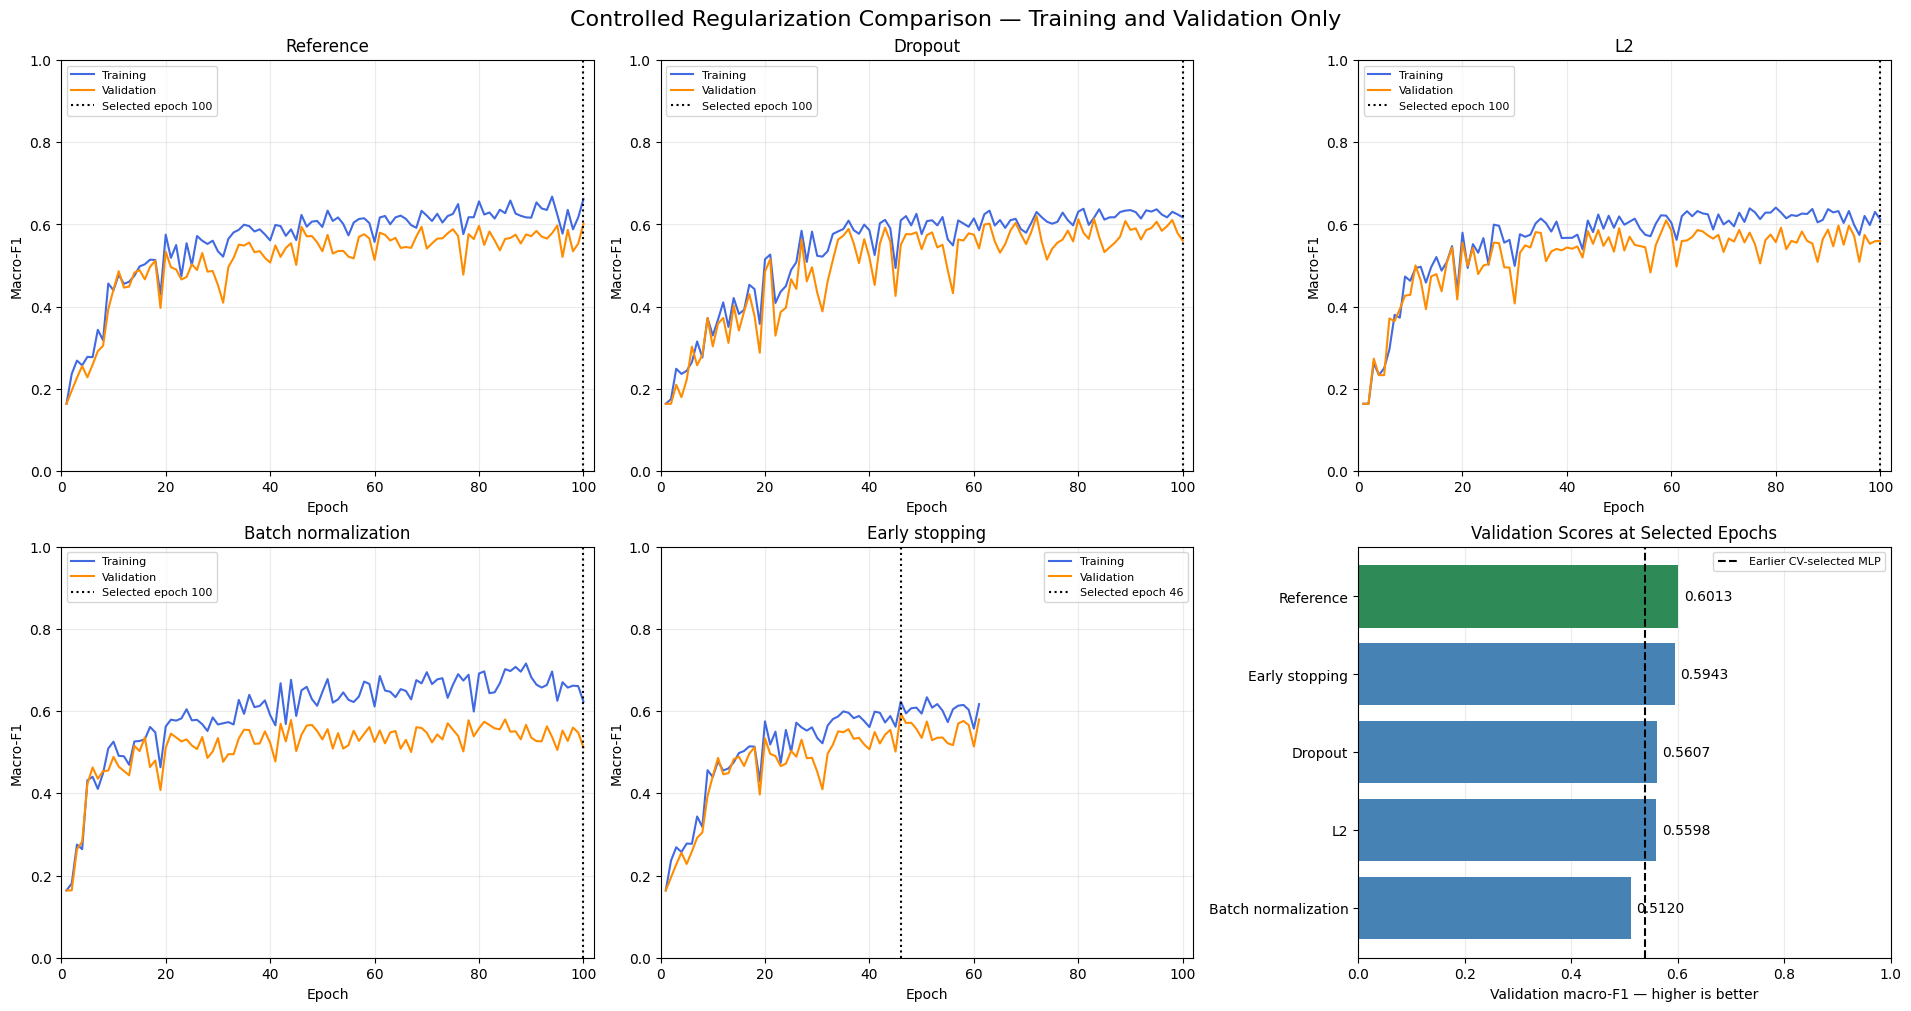

In [43]:
fig, axes = plt.subplots(
    2, 3, figsize=(19, 10), constrained_layout=True
)

for ax, (name, run) in zip(
    axes.flat[:5],
    classification_regularization_runs.items(),
):
    history = run["history"]

    ax.plot(
        history["epoch"],
        history["train_macro_f1"],
        label="Training",
        color="royalblue",
    )
    ax.plot(
        history["epoch"],
        history["validation_macro_f1"],
        label="Validation",
        color="darkorange",
    )
    ax.axvline(
        run["selected_epoch"],
        color="black",
        linestyle=":",
        label=f"Selected epoch {run['selected_epoch']}",
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro-F1")
    ax.set_xlim(0, regularization_settings["max_epochs"] + 2)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

ranking = classification_regularization_comparison.sort_values(
    "validation_macro_f1",
    ascending=False,
)

ax = axes.flat[5]
bars = ax.barh(
    ranking["experiment"],
    ranking["validation_macro_f1"],
    color=[
        "seagreen" if name == "Reference" else "steelblue"
        for name in ranking["experiment"]
    ],
)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set_xlim(0, 1)
ax.set_xlabel("Validation macro-F1 — higher is better")
ax.set_title("Validation Scores at Selected Epochs")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

cv_selected_validation_f1 = selected_classification_metrics.loc[
    selected_classification_metrics["split"].eq("validation"),
    "macro_f1",
].iloc[0]

ax.axvline(
    cv_selected_validation_f1,
    color="black",
    linestyle="--",
    label="Earlier CV-selected MLP",
)
ax.legend(fontsize=8)

fig.suptitle(
    "Controlled Regularization Comparison — Training and Validation Only",
    fontsize=16,
)

fig.savefig(
    PLOT_DIR / "maintenance_regularization_macro_f1_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

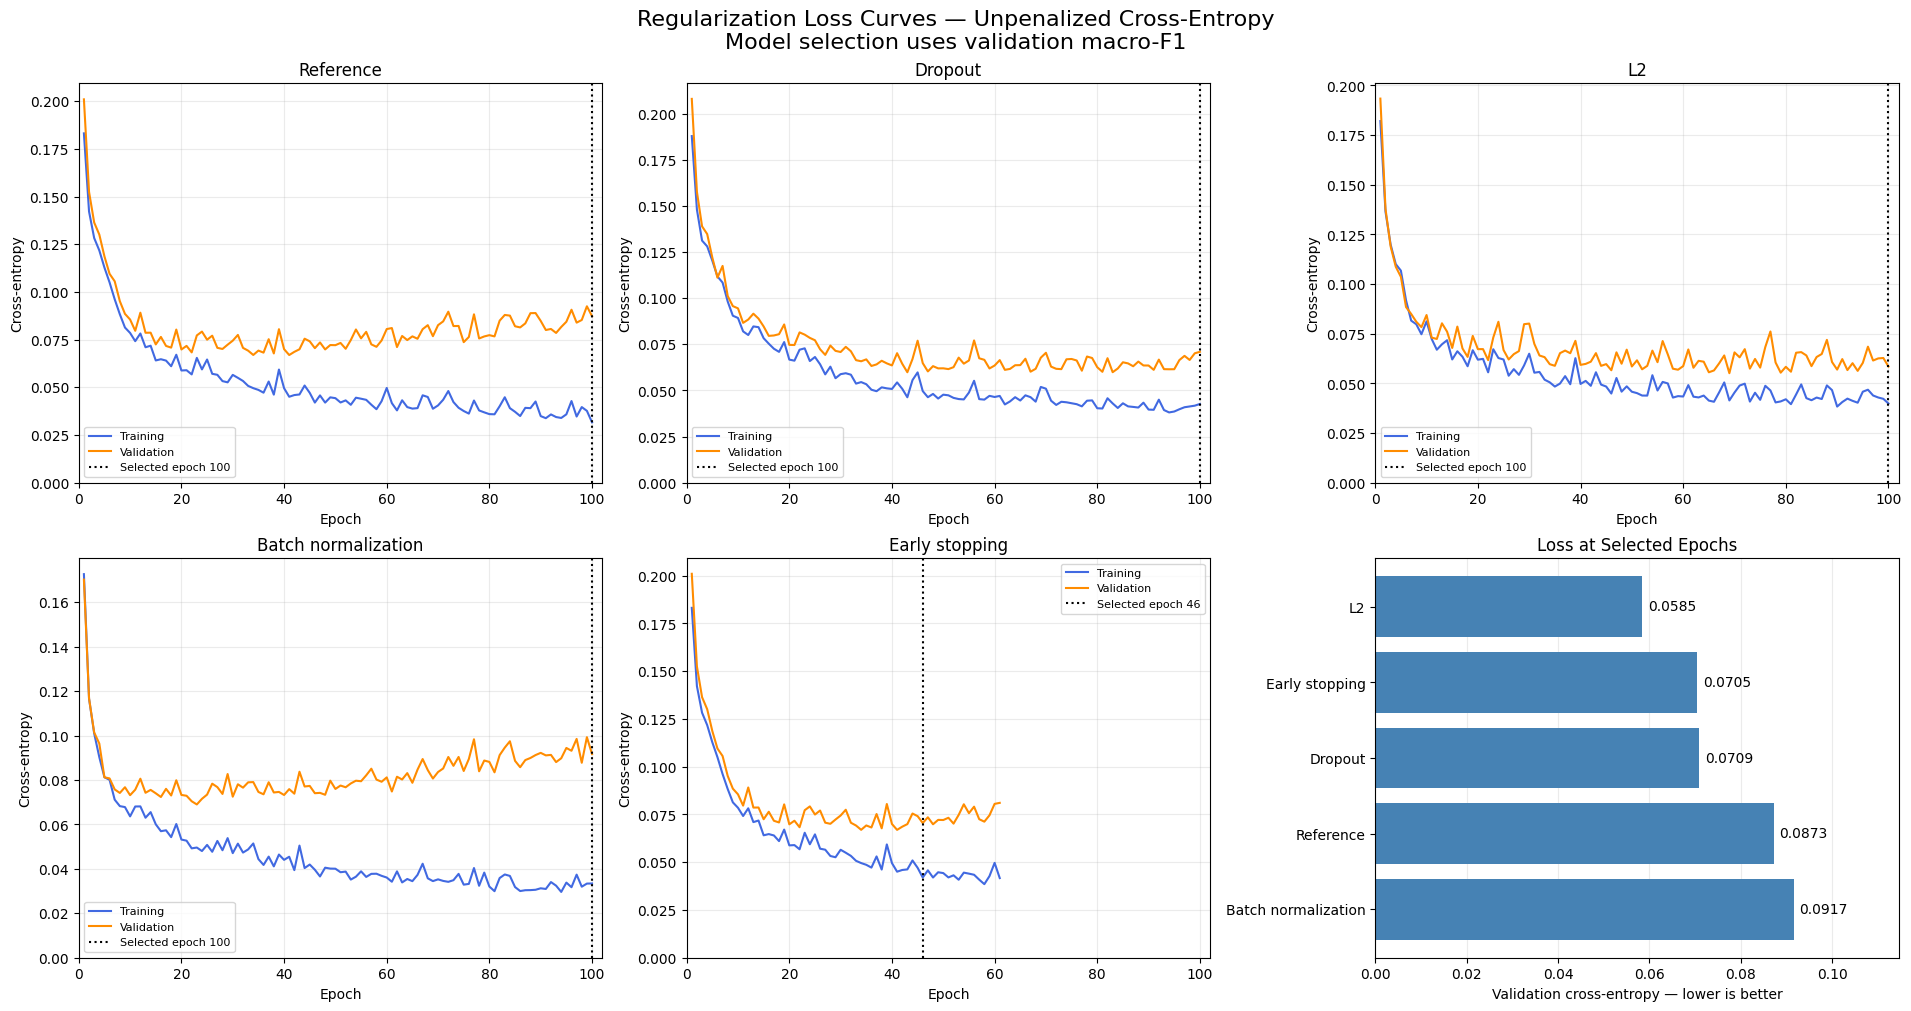

In [44]:
fig, axes = plt.subplots(
    2, 3, figsize=(19, 10), constrained_layout=True
)

for ax, (name, run) in zip(
    axes.flat[:5],
    classification_regularization_runs.items(),
):
    history = run["history"]

    ax.plot(
        history["epoch"],
        history["train_loss"],
        label="Training",
        color="royalblue",
    )
    ax.plot(
        history["epoch"],
        history["validation_loss"],
        label="Validation",
        color="darkorange",
    )
    ax.axvline(
        run["selected_epoch"],
        color="black",
        linestyle=":",
        label=f"Selected epoch {run['selected_epoch']}",
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy")
    ax.set_xlim(0, regularization_settings["max_epochs"] + 2)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

loss_ranking = classification_regularization_comparison.sort_values(
    "validation_loss"
)

ax = axes.flat[5]
bars = ax.barh(
    loss_ranking["experiment"],
    loss_ranking["validation_loss"],
    color="steelblue",
)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set_xlim(0, loss_ranking["validation_loss"].max() * 1.25)
ax.set_xlabel("Validation cross-entropy — lower is better")
ax.set_title("Loss at Selected Epochs")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.suptitle(
    "Regularization Loss Curves — Unpenalized Cross-Entropy\n"
    "Model selection uses validation macro-F1",
    fontsize=16,
)

fig.savefig(
    PLOT_DIR / "maintenance_regularization_loss_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [45]:
validation_candidates = classification_tuning_comparison.loc[
    classification_tuning_comparison["split"].eq("validation"),
    ["model", "macro_f1"],
].copy()

regularization_candidates = (
    classification_regularization_comparison[
        ["experiment", "validation_macro_f1"]
    ]
    .rename(columns={
        "experiment": "model",
        "validation_macro_f1": "macro_f1",
    })
)

validation_candidates = pd.concat(
    [validation_candidates, regularization_candidates],
    ignore_index=True,
)

assert validation_candidates["model"].is_unique

validation_candidates = validation_candidates.sort_values(
    "macro_f1",
    ascending=False,
    kind="stable",
).reset_index(drop=True)

selected_final_method = validation_candidates.iloc[0]["model"]

selected_regularization_variant = (
    classification_regularization_comparison
    .sort_values(
        "validation_macro_f1",
        ascending=False,
        kind="stable",
    )
    .iloc[0]["experiment"]
)

frozen_classification_plan = {
    "seed": SEED,
    "selection_metric": "Validation macro-F1 across all six classes",
    "selected_overall_method": selected_final_method,
    "selected_regularization_variant": selected_regularization_variant,
    "validation_ranking": validation_candidates.to_dict(orient="records"),
    "shared_regularization_settings": regularization_settings,
    "regularization_experiments": (
        regularization_experiments.reset_index().to_dict(orient="records")
    ),
    "selected_checkpoints": {
        name: {
            "selected_epoch": int(run["selected_epoch"]),
            "epochs_run": int(run["epochs_run"]),
        }
        for name, run in classification_regularization_runs.items()
    },
    "early_stopping": {
        "metric": "Validation macro-F1",
        "patience": EARLY_STOPPING_PATIENCE,
        "min_delta": EARLY_STOPPING_MIN_DELTA,
        "restore": "Highest observed validation macro-F1; earliest tie",
    },
    "test_evaluation": {
        "samples": len(test),
        "models": validation_candidates["model"].tolist(),
        "metrics": ["accuracy", "macro_recall", "macro_f1"],
        "per_class_reports": True,
        "confusion_matrices": True,
        "refit_before_evaluation": False,
        "epoch_curves": (
            "Evaluate stored regularization checkpoints for reporting only; "
            "restore previously selected checkpoints afterward."
        ),
        "test_based_reselection": False,
    },
    "test_evaluated_at_freeze": False,
}

frozen_plan_path = (
    RESULTS_DIR / "maintenance_regularization_frozen_plan.json"
)

frozen_plan_path.write_text(
    json.dumps(frozen_classification_plan, indent=2),
    encoding="utf-8",
)

display(validation_candidates.round(6))

print("Selected overall method:", selected_final_method)
print("Selected regularization variant:", selected_regularization_variant)
print(
    "Selected epoch:",
    classification_regularization_runs[
        selected_regularization_variant
    ]["selected_epoch"],
)
print("Saved frozen evaluation plan:", frozen_plan_path)
print("Test data have not yet been evaluated.")

,model,macro_f1
0,Reference,0.601341
1,Early stopping,0.594252
2,Dropout,0.560704
3,L2,0.559797
4,CV-selected MLP,0.539219
5,Batch normalization,0.511985
6,Unresampled MLP,0.500755
7,Oversampled MLP,0.482743
8,Majority-class baseline,0.163698


Selected overall method: Reference
Selected regularization variant: Reference
Selected epoch: 100
Saved frozen evaluation plan: /kaggle/working/results/maintenance_regularization_frozen_plan.json
Test data have not yet been evaluated.


## 10. Frozen-model train/test curves and final metrics

Evaluate frozen models and saved checkpoints on the original test partition. Test results do not change model or epoch selection.

In [46]:
frozen_plan = json.loads(frozen_plan_path.read_text(encoding="utf-8"))

assert frozen_plan["selected_overall_method"] == "Reference"
assert frozen_plan["selected_checkpoints"]["Reference"]["selected_epoch"] == 100

X_test = preprocessor.transform(test[FEATURES]).astype(np.float32)
y_test = label_encoder.transform(test[TARGET]).astype(np.int64)
X_test_device = torch.from_numpy(X_test).to(DEVICE)

assert X_test.shape == (2000, 8)
assert np.isfinite(X_test).all()

classification_model.load_state_dict(baseline_classification_state)
balanced_model.load_state_dict(balanced_classification_state)
selected_classifier.named_steps["net"].module_.load_state_dict(
    selected_classification_state
)

test_predictions_by_model = {
    "Majority-class baseline": dummy_model.predict(X_test),
    "CV-selected MLP": selected_classifier.predict(test[FEATURES]),
}

torch_models = {
    "Unresampled MLP": classification_model,
    "Oversampled MLP": balanced_model,
}

for name, run in classification_regularization_runs.items():
    selected_epoch = frozen_plan["selected_checkpoints"][name]["selected_epoch"]
    run["model"].load_state_dict(run["checkpoints"][selected_epoch])
    torch_models[name] = run["model"]

with torch.no_grad():
    for name, model in torch_models.items():
        model.eval()
        logits = model(X_test_device)
        assert torch.isfinite(logits).all()

        test_predictions_by_model[name] = (
            logits.argmax(dim=1).cpu().numpy()
        )

assert set(test_predictions_by_model) == set(
    frozen_plan["test_evaluation"]["models"]
)

final_test_rows = []

for name in frozen_plan["test_evaluation"]["models"]:
    predictions = test_predictions_by_model[name]

    assert predictions.shape == y_test.shape
    assert np.isin(predictions, np.arange(NUM_CLASSES)).all()

    final_test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "macro_recall": balanced_accuracy_score(y_test, predictions),
        "macro_f1": f1_score(
            y_test,
            predictions,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0,
        ),
    })

classification_final_test_metrics = pd.DataFrame(final_test_rows)

classification_final_test_predictions = pd.DataFrame({
    "UDI": maintenance.loc[test.index, "UDI"].to_numpy(),
    "true_class": label_encoder.inverse_transform(y_test),
})

for name in frozen_plan["test_evaluation"]["models"]:
    classification_final_test_predictions[name] = (
        label_encoder.inverse_transform(test_predictions_by_model[name])
    )

classification_final_test_metrics.to_csv(
    RESULTS_DIR / "maintenance_final_test_metrics.csv",
    index=False,
)
classification_final_test_predictions.to_csv(
    RESULTS_DIR / "maintenance_final_test_predictions.csv",
    index=False,
)

print("FINAL TEST RESULTS")
display(classification_final_test_metrics.round(6))

print("Test samples:", len(y_test))
print("Preselected method:", frozen_plan["selected_overall_method"])
print("PASS: fixed models evaluated; no training or reselection performed.")

FINAL TEST RESULTS


,model,accuracy,macro_recall,macro_f1
0,Reference,0.9845,0.531390,0.570124
1,Early stopping,0.9870,0.594551,0.599975
2,Dropout,0.9830,0.509274,0.554148
3,L2,0.9800,0.504719,0.522181
4,CV-selected MLP,0.9800,0.589916,0.559920
5,Batch normalization,0.9815,0.464241,0.520147
6,Unresampled MLP,0.9780,0.419149,0.485091
7,Oversampled MLP,0.8695,0.664160,0.463491
8,Majority-class baseline,0.9650,0.166667,0.163698


Test samples: 2000
Preselected method: Reference
PASS: fixed models evaluated; no training or reselection performed.


PRESELECTED MODEL: Reference


,precision,recall,f1-score,support
class_or_summary,,,,
Heat Dissipation Failure,0.9474,0.8182,0.8780,22.0000
No Failure,0.9862,0.9984,0.9923,1930.0000
Overstrain Failure,0.9167,0.6875,0.7857,16.0000
Power Failure,0.8667,0.6842,0.7647,19.0000
Random Failures,0.0000,0.0000,0.0000,4.0000
Tool Wear Failure,0.0000,0.0000,0.0000,9.0000
accuracy,0.9845,0.9845,0.9845,0.9845
macro avg,0.6195,0.5314,0.5701,2000.0000
weighted avg,0.9777,0.9845,0.9808,2000.0000


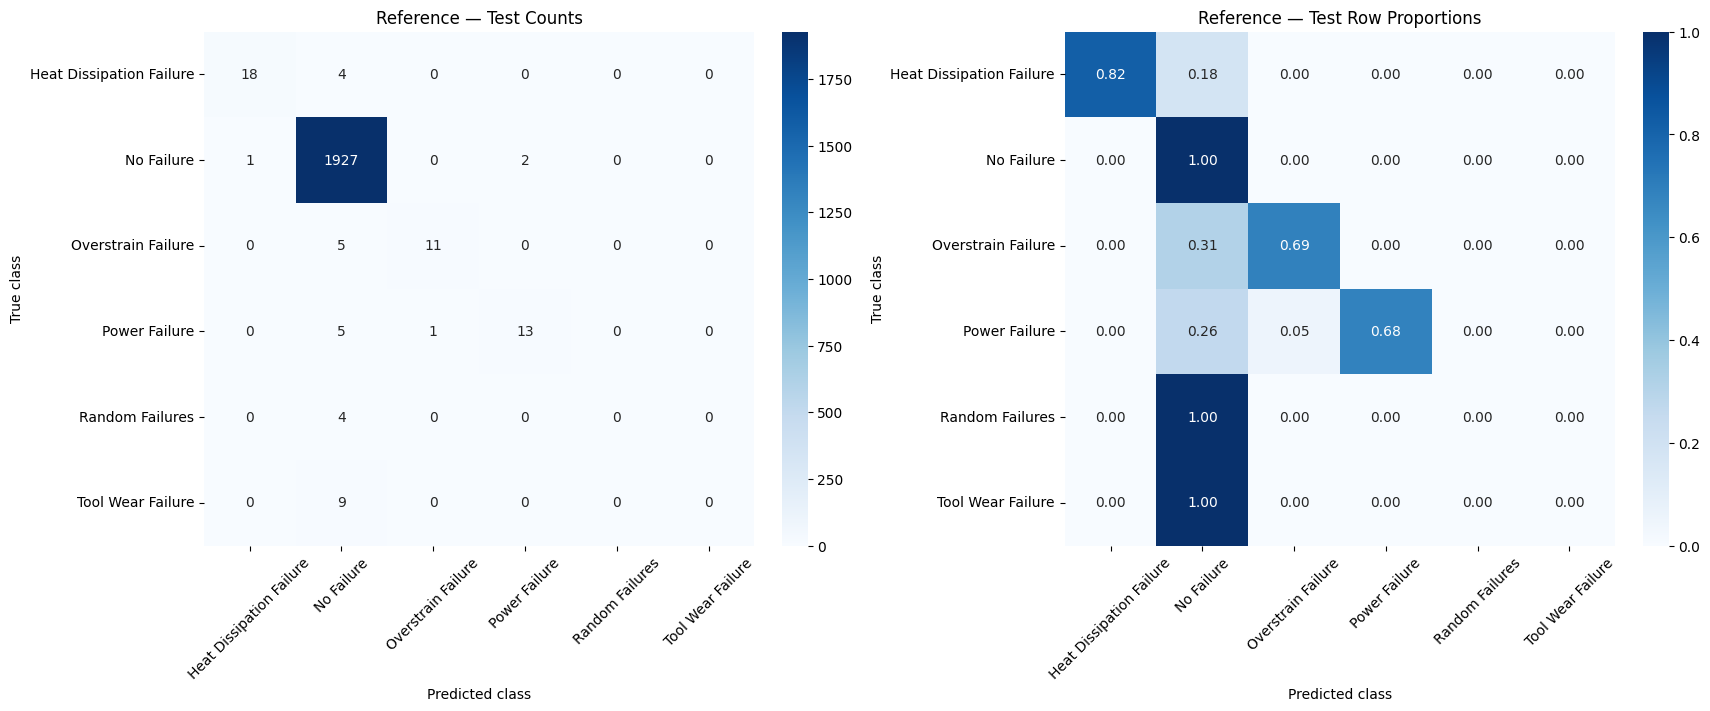

PASS: all nine per-class reports match the final test metrics.


In [47]:
test_report_tables = []
test_confusion_tables = []

for name in frozen_plan["test_evaluation"]["models"]:
    predictions = test_predictions_by_model[name]

    report = pd.DataFrame(
        classification_report(
            y_test,
            predictions,
            labels=np.arange(NUM_CLASSES),
            target_names=label_encoder.classes_,
            output_dict=True,
            zero_division=0,
        )
    ).T
    report.index.name = "class_or_summary"

    recorded = classification_final_test_metrics.loc[
        classification_final_test_metrics["model"].eq(name)
    ].iloc[0]

    np.testing.assert_allclose(
        report.loc["macro avg", "f1-score"],
        recorded["macro_f1"],
    )
    np.testing.assert_allclose(
        report.loc["macro avg", "recall"],
        recorded["macro_recall"],
    )

    report_export = report.reset_index()
    report_export.insert(0, "model", name)
    test_report_tables.append(report_export)

    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES),
    )

    matrix_export = pd.DataFrame(
        matrix,
        index=label_encoder.classes_,
        columns=label_encoder.classes_,
    ).rename_axis("true_class").reset_index()
    matrix_export.insert(0, "model", name)
    test_confusion_tables.append(matrix_export)

classification_test_reports = pd.concat(
    test_report_tables, ignore_index=True
)
classification_test_confusions = pd.concat(
    test_confusion_tables, ignore_index=True
)

classification_test_reports.to_csv(
    RESULTS_DIR / "maintenance_final_test_classification_reports.csv",
    index=False,
)
classification_test_confusions.to_csv(
    RESULTS_DIR / "maintenance_final_test_confusion_matrices.csv",
    index=False,
)

preselected_name = frozen_plan["selected_overall_method"]

print("PRESELECTED MODEL:", preselected_name)
display(
    classification_test_reports.loc[
        classification_test_reports["model"].eq(preselected_name)
    ].drop(columns="model").set_index("class_or_summary").round(4)
)

preselected_cm = confusion_matrix(
    y_test,
    test_predictions_by_model[preselected_name],
    labels=np.arange(NUM_CLASSES),
)
preselected_cm_normalized = (
    preselected_cm / preselected_cm.sum(axis=1, keepdims=True)
)

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7), constrained_layout=True
)

for ax, values, fmt, title in [
    (axes[0], preselected_cm, "d", "Test Counts"),
    (axes[1], preselected_cm_normalized, ".2f", "Test Row Proportions"),
]:
    sns.heatmap(
        values,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        vmin=0,
        vmax=1 if fmt == ".2f" else None,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax,
    )
    ax.set_title(f"{preselected_name} — {title}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

fig.savefig(
    PLOT_DIR / "maintenance_selected_test_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: all nine per-class reports match the final test metrics.")

In [48]:
classification_test_epoch_rows = []
y_test_device = torch.from_numpy(y_test).to(DEVICE)

for name, run in classification_regularization_runs.items():
    model = run["model"]
    selected_epoch = frozen_plan["selected_checkpoints"][name]["selected_epoch"]

    try:
        for epoch, checkpoint in sorted(run["checkpoints"].items()):
            model.load_state_dict(checkpoint)
            model.eval()

            with torch.no_grad():
                logits = model(X_test_device)
                predictions = logits.argmax(dim=1).cpu().numpy()

                test_loss = nn.functional.cross_entropy(
                    logits, y_test_device
                ).item()

            training_row = run["history"].loc[
                run["history"]["epoch"].eq(epoch)
            ].iloc[0]

            classification_test_epoch_rows.append({
                "experiment": name,
                "epoch": epoch,
                "selected_epoch": selected_epoch,
                **{
                    f"train_{metric}": float(training_row[f"train_{metric}"])
                    for metric in [
                        "loss", "accuracy", "macro_recall", "macro_f1"
                    ]
                },
                "test_loss": test_loss,
                "test_accuracy": accuracy_score(y_test, predictions),
                "test_macro_recall": balanced_accuracy_score(
                    y_test, predictions
                ),
                "test_macro_f1": f1_score(
                    y_test,
                    predictions,
                    labels=np.arange(NUM_CLASSES),
                    average="macro",
                    zero_division=0,
                ),
            })

    finally:
        model.load_state_dict(run["checkpoints"][selected_epoch])
        model.eval()

    with torch.no_grad():
        restored_predictions = (
            model(X_test_device).argmax(dim=1).cpu().numpy()
        )

    np.testing.assert_array_equal(
        restored_predictions,
        test_predictions_by_model[name],
    )

classification_test_epoch_history = pd.DataFrame(
    classification_test_epoch_rows
)

assert np.isfinite(
    classification_test_epoch_history.select_dtypes(
        include="number"
    ).to_numpy()
).all()

for name, run in classification_regularization_runs.items():
    selected_row = classification_test_epoch_history.loc[
        classification_test_epoch_history["experiment"].eq(name)
        & classification_test_epoch_history["epoch"].eq(
            run["selected_epoch"]
        )
    ].iloc[0]

    final_row = classification_final_test_metrics.loc[
        classification_final_test_metrics["model"].eq(name)
    ].iloc[0]

    for metric in ["accuracy", "macro_recall", "macro_f1"]:
        np.testing.assert_allclose(
            selected_row[f"test_{metric}"],
            final_row[metric],
        )

classification_test_epoch_history.to_csv(
    RESULTS_DIR / "maintenance_regularization_test_epoch_history.csv",
    index=False,
)

display(
    classification_test_epoch_history.groupby("experiment")
    .size()
    .to_frame("epochs")
)

print("PASS: selected-epoch metrics match the final test table.")
print("All models restored to their previously selected checkpoints.")
print("Test curves are for reporting only.")

,epochs
experiment,
Batch normalization,100
Dropout,100
Early stopping,61
L2,100
Reference,100


PASS: selected-epoch metrics match the final test table.
All models restored to their previously selected checkpoints.
Test curves are for reporting only.


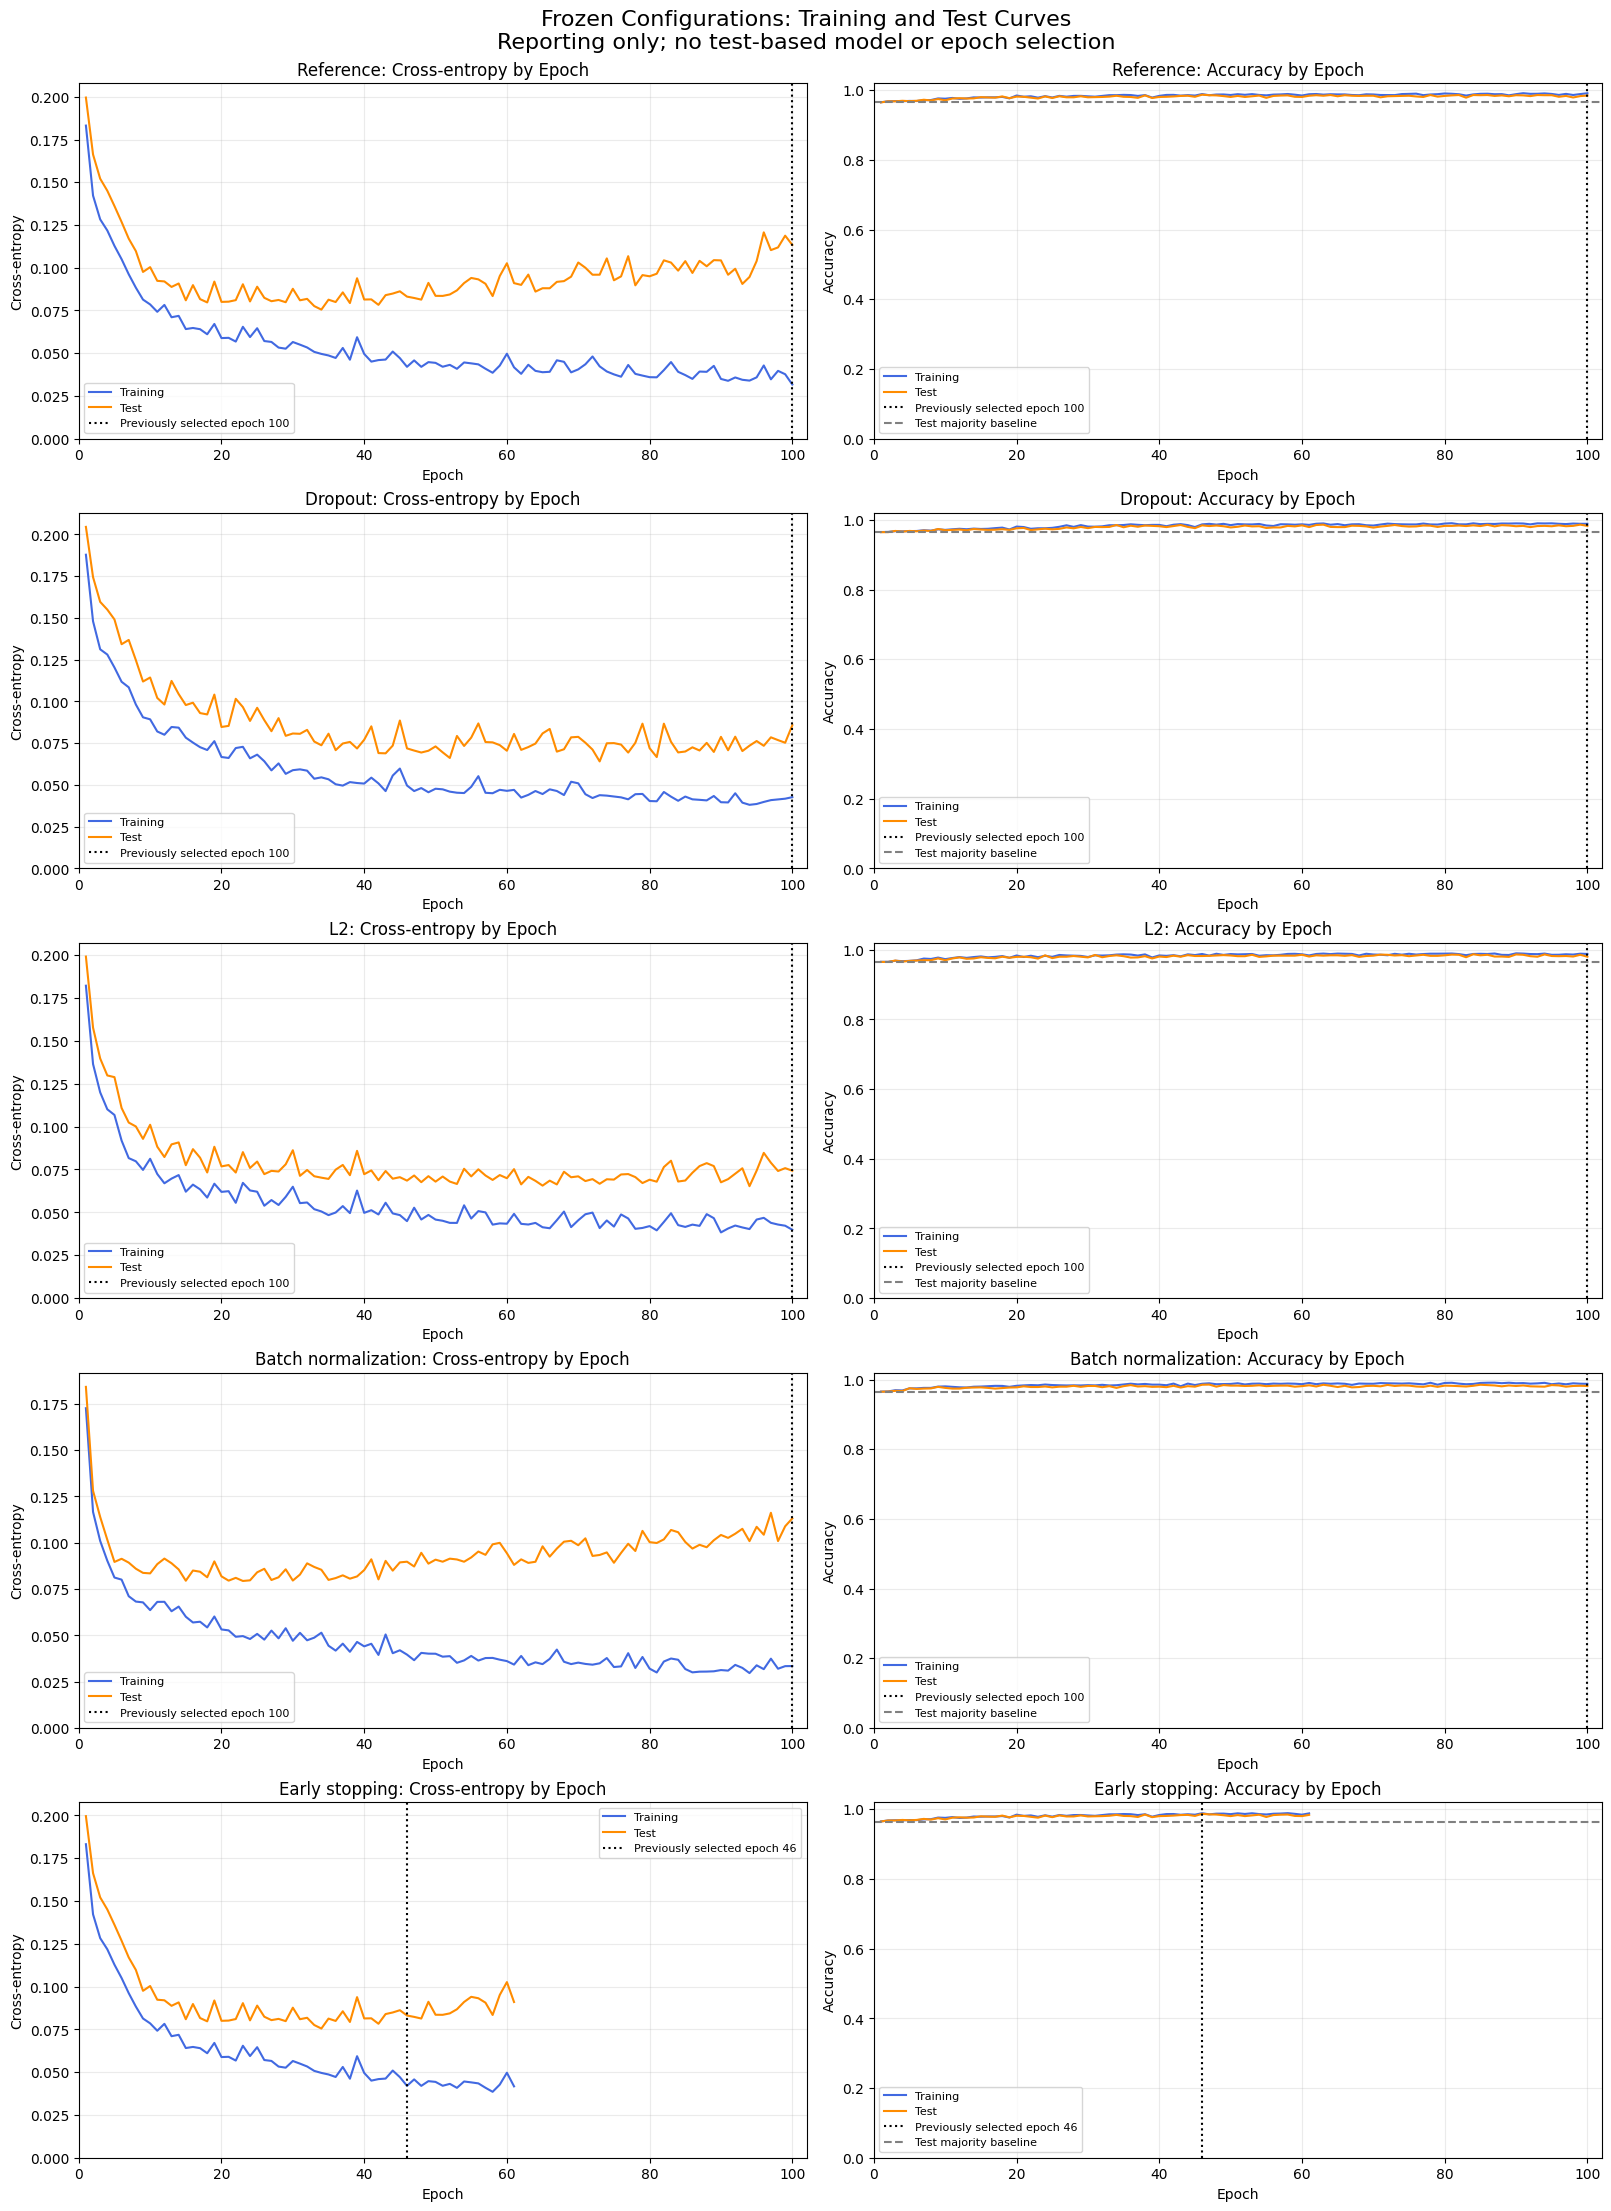

In [49]:
experiment_names = list(classification_regularization_runs)

fig, axes = plt.subplots(
    len(experiment_names),
    2,
    figsize=(16, 22),
    constrained_layout=True,
)

test_dummy_accuracy = classification_final_test_metrics.loc[
    classification_final_test_metrics["model"].eq(
        "Majority-class baseline"
    ),
    "accuracy",
].iloc[0]

for row, name in enumerate(experiment_names):
    history = classification_test_epoch_history.loc[
        classification_test_epoch_history["experiment"].eq(name)
    ].sort_values("epoch")

    selected_epoch = frozen_plan["selected_checkpoints"][name]["selected_epoch"]

    for ax, metric, ylabel in [
        (axes[row, 0], "loss", "Cross-entropy"),
        (axes[row, 1], "accuracy", "Accuracy"),
    ]:
        ax.plot(
            history["epoch"],
            history[f"train_{metric}"],
            label="Training",
            color="royalblue",
        )
        ax.plot(
            history["epoch"],
            history[f"test_{metric}"],
            label="Test",
            color="darkorange",
        )
        ax.axvline(
            selected_epoch,
            color="black",
            linestyle=":",
            label=f"Previously selected epoch {selected_epoch}",
        )

        if metric == "accuracy":
            ax.axhline(
                test_dummy_accuracy,
                color="gray",
                linestyle="--",
                label="Test majority baseline",
            )
            ax.set_ylim(0, 1.02)
        else:
            ax.set_ylim(bottom=0)

        ax.set_title(f"{name}: {ylabel} by Epoch")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.set_xlim(0, regularization_settings["max_epochs"] + 2)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(
    "Frozen Configurations: Training and Test Curves\n"
    "Reporting only; no test-based model or epoch selection",
    fontsize=16,
)

fig.savefig(
    PLOT_DIR / "maintenance_regularization_train_test_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

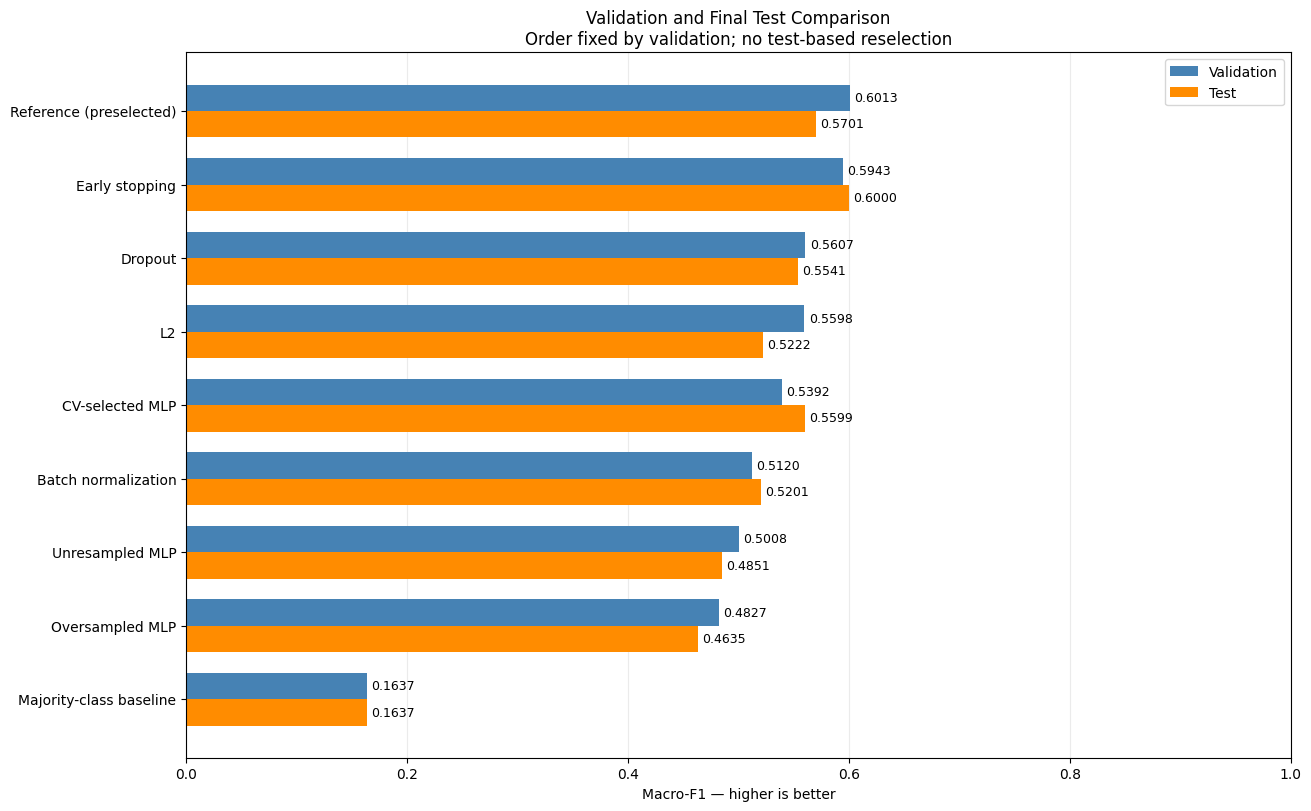

In [50]:
final_score_comparison = (
    validation_candidates.rename(columns={"macro_f1": "validation_macro_f1"})
    .merge(
        classification_final_test_metrics[["model", "macro_f1"]].rename(
            columns={"macro_f1": "test_macro_f1"}
        ),
        on="model",
        how="left",
        validate="one_to_one",
        sort=False,
    )
)

assert len(final_score_comparison) == 9
assert final_score_comparison.notna().all().all()

positions = np.arange(len(final_score_comparison))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(13, 8), constrained_layout=True)

validation_bars = ax.barh(
    positions - bar_height / 2,
    final_score_comparison["validation_macro_f1"],
    height=bar_height,
    label="Validation",
    color="steelblue",
)
test_bars = ax.barh(
    positions + bar_height / 2,
    final_score_comparison["test_macro_f1"],
    height=bar_height,
    label="Test",
    color="darkorange",
)

labels = [
    f"{name} (preselected)"
    if name == frozen_plan["selected_overall_method"]
    else name
    for name in final_score_comparison["model"]
]

ax.set_yticks(positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.bar_label(validation_bars, fmt="%.4f", padding=3, fontsize=9)
ax.bar_label(test_bars, fmt="%.4f", padding=3, fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1 — higher is better")
ax.set_title(
    "Validation and Final Test Comparison\n"
    "Order fixed by validation; no test-based reselection"
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

fig.savefig(
    PLOT_DIR / "maintenance_final_macro_f1_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

final_score_comparison.to_csv(
    RESULTS_DIR / "maintenance_final_macro_f1_comparison.csv",
    index=False,
)

## 11. Interpretation and exported results

### Regularization and final evaluation conclusions

Five variants were compared using the original, unresampled training
data, training-fitted preprocessing, hidden layers (32, 16), Adam with
learning rate 0.005, batch size 64, and a maximum of 100 epochs.

Dropout used probability 0.1. Explicit L2 used coefficient 0.0001 on
Linear weights only. Batch normalization was applied before ReLU.
Early stopping monitored validation macro-F1 with patience 15 and
minimum improvement 0.0001.

Reference had the highest validation macro-F1 (0.601341), so its
epoch-100 checkpoint was selected before test evaluation. None of
the tested regularization variants improved on this direct control.
Early stopping ran for 61 epochs and restored epoch 46, achieving
validation macro-F1 of 0.594252.

L2 achieved the lowest validation cross-entropy, but model selection
used macro-F1. Reference and batch normalization showed widening
training–validation loss gaps. Lower cross-entropy did not always
correspond to higher macro-F1.

### Final test results

The preselected Reference model achieved:

- Accuracy: 0.984500
- Macro-recall: 0.531390
- Macro-F1: 0.570124

It correctly classified 18/22 Heat Dissipation, 11/16 Overstrain,
and 13/19 Power Failure examples. It produced three false alarms
among 1,930 No Failure records. However, all four Random Failures
and all nine Tool Wear failures were classified as No Failure.

Early stopping achieved the highest observed test macro-F1
(0.599975). This is a reporting result; Reference remains the model
selected using validation. No model or epoch was reselected using
test results.

Oversampling achieved the highest test macro-recall (0.664160),
but its macro-F1 was 0.463491 and accuracy was 0.869500.
Its increased sensitivity came with more false alarms.

### Reporting and limitations

Training/test curves were computed from 461 saved epoch checkpoints.
All models were restored to their previously selected checkpoints,
and selected-epoch metrics matched the final test table. No training
or test-based checkpoint selection occurred during curve generation.

Results describe one stratified split, one seed, and the tested
configurations. Minority-class estimates are uncertain because
supports are small. High accuracy does not imply reliable detection
of every failure class.

The classification experiments are complete. A fresh-session Kaggle
rerun and final repository/report review remain.